# Saúde da mulher na África Subsaariana

Analisamos escolaridade, contracepção, pré-natal, parto, vacinação infantil e condições de moradia em 37 países.

## 1. Dados utilizados

Os dados vieram do DHS, em arquivos Stata, e foram convertidos para CSV. Usamos os seis arquivos da pasta dados/relevantes: IR, HR, PR, BR, KR e MR. Eles reúnem entrevistas com mulheres e homens, além de informações sobre domicílios, moradores, nascimentos e crianças.

O banco tem 13 tabelas. Fizemos dez consultas SQL e usamos tabelas e gráficos para analisar os resultados.

In [1]:
import csv
import gzip
import hashlib
import sqlite3
from contextlib import closing
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter
from statistics import median

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from database_python.carregar_sqlite import manifest_rows, columns_for, PREFIX_COLUMNS
from database_python.relatorio_notebook import (
    construir_banco, barras, mapa, pares, comparar_residencias,
    verificar_sensibilidade, comparar_prenatal,
)

raiz = Path.cwd().resolve()
if not (raiz / 'docs/esquemas_csv.csv').is_file():
    raise FileNotFoundError('Abra o notebook com o diretório de trabalho na raiz do repositório.')
dados = raiz / 'dados/relevantes'
BANCO = raiz / 'tmp/ibd012/saude_mulher_eda.db'
BANCO.parent.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 25)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})

def assinatura(arquivo):
    with Path(arquivo).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()


def consulta(sql):
    display(Markdown('```sql\n' + sql.strip() + '\n```'))
    resultado = pd.read_sql_query(sql, conn)
    display(resultado.head(15))
    print(f'{len(resultado):,} linhas no resultado completo; até 15 exibidas.')
    return resultado

def exibir(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

## 2. Organização do banco

Cada país tem suas pesquisas e seus domicílios. As mulheres, os homens entrevistados e os moradores estão ligados aos domicílios. Os nascimentos estão ligados às mulheres. Usamos a pesquisa, o domicílio e o número de cada pessoa para não confundir registros de países diferentes.

| Relação | Unidade / chave | Relacionamento |
| --- | --- | --- |
| Pais | País / código | 1:N Levantamento |
| Levantamento | Pesquisa / país + fase | 1:N Domicilio |
| Domicilio | Domicílio / pesquisa + conglomerado + número | 1:N Mulher, Morador e Parceiro |
| Mulher | Entrevistada / domicílio + linha | 1:1 Entrevista; 1:N Nascimento |
| Entrevista | Entrevista feminina / mulher | Peso e data da pesquisa |
| Nascimento | Nascimento / mulher + índice | 1:0..1 Crianca |
| Crianca | Registro KR / nascimento | M:N Vacina_Remedio via Crianca_Vacina |
| Morador | Pessoa PR / domicílio + linha | Contexto da composição domiciliar |
| Parceiro | Homem MR / domicílio + linha | Não implica casal pareado com uma mulher |
| Metodo | Método / identificador | M:N Mulher via Conhecimento_Metodo |
| Conhecimento_Metodo | Mulher + método | Nível da resposta, inclusive desconhecimento |
| Vacina_Remedio | Vacina / identificador | Catálogo h2–h9 |
| Crianca_Vacina | Criança + vacina | Status original da resposta |

As respostas sobre métodos contraceptivos e vacinas ficam em tabelas separadas, ligadas às mulheres e às crianças. Assim, não precisamos repetir os mesmos dados em várias colunas.

Quando falta o registro do domicílio no arquivo HR, usamos as informações disponíveis nos arquivos IR ou MR. Também incluímos nascimentos que aparecem no KR e não estão no BR. Dados ausentes continuam em branco. Os homens entrevistados não são necessariamente parceiros das mulheres da mesma casa.

In [2]:
DDL = """
CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
CREATE TABLE Domicilio(
  id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
  cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
  residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
  eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo','MR_sem_HR')),
  UNIQUE(levantamento_id,cluster,numero));
CREATE TABLE Mulher(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Parceiro(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  total_filhos INTEGER, idade_primeiro_filho INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Entrevista(
  mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
  data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
  coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
CREATE TABLE Nascimento(
  id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
  ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
  consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
  assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
CREATE TABLE Crianca(
  nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
  diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
CREATE TABLE Vacina_Remedio(
  id INTEGER PRIMARY KEY, codigo TEXT NOT NULL UNIQUE, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Crianca_Vacina(
  nascimento_id TEXT NOT NULL REFERENCES Crianca(nascimento_id),
  vacina_id INTEGER NOT NULL REFERENCES Vacina_Remedio(id),
  status_codigo INTEGER NOT NULL CHECK(status_codigo BETWEEN 0 AND 9),
  PRIMARY KEY(nascimento_id,vacina_id)) WITHOUT ROWID;
CREATE TABLE Morador(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Metodo(
  id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
CREATE TABLE Conhecimento_Metodo(
  mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
  nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
"""
display(Markdown("```sql\n" + DDL + "\n```"))

```sql

CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
CREATE TABLE Domicilio(
  id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
  cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
  residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
  eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo','MR_sem_HR')),
  UNIQUE(levantamento_id,cluster,numero));
CREATE TABLE Mulher(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Parceiro(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  total_filhos INTEGER, idade_primeiro_filho INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Entrevista(
  mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
  data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
  coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
CREATE TABLE Nascimento(
  id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
  ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
  consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
  assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
CREATE TABLE Crianca(
  nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
  diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
CREATE TABLE Vacina_Remedio(
  id INTEGER PRIMARY KEY, codigo TEXT NOT NULL UNIQUE, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Crianca_Vacina(
  nascimento_id TEXT NOT NULL REFERENCES Crianca(nascimento_id),
  vacina_id INTEGER NOT NULL REFERENCES Vacina_Remedio(id),
  status_codigo INTEGER NOT NULL CHECK(status_codigo BETWEEN 0 AND 9),
  PRIMARY KEY(nascimento_id,vacina_id)) WITHOUT ROWID;
CREATE TABLE Morador(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Metodo(
  id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
CREATE TABLE Conhecimento_Metodo(
  mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
  nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;

```

## 3. Importação dos dados

Os dados são inseridos em grupos de 10 mil linhas. Campos vazios ficam como NULL no SQLite. Não preenchemos respostas ausentes com médias nem excluímos mulheres por falta de informação. Antes de concluir a carga, conferimos as quantidades e as ligações entre as tabelas.

In [3]:
COLUNAS = {
    "IR": ["v001", "v002", "v003", "v024", "v025", "v190", "v012", "v106", "v201", "v212",
           "v006", "v007", "v008", "v005", "v312"] + [f"v304_{i:02d}" for i in range(1, 10)],
    "HR": ["hv001", "hv002", "hv024", "hv025", "hv270", "hv206", "hv201", "hv009"],
    "PR": ["hv001", "hv002", "hvidx", "hv104", "hv105", "hv106", "hv101"],
    "BR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "m3a", "m3b"],
    "KR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "b8", "h11", "h1",
           "h2", "h3", "h4", "h5", "h6", "h7", "h8", "h9"],
    "MR": ["mv001", "mv002", "mv003", "mv024", "mv025", "mv190", "mv012", "mv106", "mv201", "mv212"],
}
TABELAS_RECODE = dict(IR="Mulher", HR="Domicilio", PR="Morador", BR="Nascimento", KR="Crianca", MR="Parceiro")


def ler_csvs(dados, origem, manifesto):
    """Lê CSVs gzip em lotes, alinhando as colunas de cada país pelo manifesto."""
    origem.executescript("CREATE TABLE Pais(pais_codigo TEXT PRIMARY KEY, nome_pais TEXT); "
                        "CREATE TABLE Levantamento(levantamento_id TEXT PRIMARY KEY, pais_codigo TEXT, fase TEXT);")
    paises = {m["pais_codigo"]: m["pais_nome"] for m in manifesto}
    pesquisas = {(m["pais_codigo"], m["fase"]) for m in manifesto}
    origem.executemany("INSERT INTO Pais VALUES (?, ?)", paises.items())
    origem.executemany("INSERT INTO Levantamento VALUES (?, ?, ?)",
                       [(f"{pais}_{fase}", pais, fase) for pais, fase in sorted(pesquisas)])
    for recode, selecionadas in COLUNAS.items():
        itens = [m for m in manifesto if m["recode"] == recode]
        if not itens:
            raise ValueError(f"Recode obrigatório ausente no manifesto: {recode}")
        tabela = TABELAS_RECODE[recode]
        colunas = PREFIX_COLUMNS + selecionadas
        tipos = [f'"{c}" TEXT' for c in PREFIX_COLUMNS] + [f'"{c}" NUMERIC' for c in selecionadas]
        origem.execute(f"CREATE TABLE {tabela} ({', '.join(tipos)})")
        inserir = f"INSERT INTO {tabela} VALUES ({', '.join('?' for _ in colunas)})"
        with gzip.open(dados / f"{recode}.csv.gz", "rt", encoding="utf-8-sig", newline="") as arquivo:
            leitor = csv.reader(arquivo)
            if next(leitor, None) != columns_for(itens[0]):
                raise ValueError(f"Cabeçalho incompatível: {recode}")
            for item in itens:
                esquema = columns_for(item)
                esperado = [item["pais_codigo"], item["pais_nome"],
                            f"{item['pais_codigo']}_{item['fase']}", item["fase"], item["arquivo_origem"]]
                lote = []
                for _ in range(int(item["linhas"])):
                    linha = next(leitor, None)
                    if linha is None or len(linha) != len(esquema) or linha[:5] != esperado:
                        raise ValueError(f"Linha incompatível com o manifesto: {recode}/{item['pais_codigo']}")
                    registro = dict(zip(esquema, linha))
                    lote.append([registro.get(coluna) or None for coluna in colunas])
                    if len(lote) == 10000:
                        origem.executemany(inserir, lote)
                        lote.clear()
                origem.executemany(inserir, lote)
            if next(leitor, None) is not None:
                raise ValueError(f"Linhas excedentes: {recode}")
    origem.commit()

In [4]:
manifesto_path = raiz / 'docs/esquemas_csv.csv'
manifesto = [m for m in manifest_rows(manifesto_path) if m['recode'] in COLUNAS]
esperados = {recode: 0 for recode in COLUNAS}
for item in manifesto:
    esperados[item['recode']] += int(item['linhas'])

fontes = [manifesto_path] + [dados / f'{r}.csv.gz' for r in COLUNAS]
assinaturas_antes = {str(p): assinatura(p) for p in fontes}
inicio_carga = perf_counter()
if 'conn' in globals():
    conn.close()
with TemporaryDirectory(prefix='ibd012_') as pasta:
    preparacao = Path(pasta) / 'preparacao.db'
    with closing(sqlite3.connect(preparacao)) as bruto:
        ler_csvs(dados, bruto, manifesto)
        auditoria = []
        for recode, tabela in TABELAS_RECODE.items():
            importado = bruto.execute(f'SELECT COUNT(*) FROM {tabela}').fetchone()[0]
            assert importado == esperados[recode], f'Contagem incorreta em {recode}'
            auditoria.append([recode, tabela, esperados[recode], importado])
        auditoria_carga = pd.DataFrame(auditoria, columns=['recode', 'tabela', 'esperado', 'importado'])
    construir_banco(preparacao, BANCO, suplementos=(), ddl=DDL)

conn = sqlite3.connect(BANCO)
conn.execute('PRAGMA foreign_keys=ON')
display(auditoria_carga)
print(f'Banco criado: {BANCO} ({perf_counter() - inicio_carga:.1f} s)')

,recode,tabela,esperado,importado
0,IR,Mulher,407600,407600
1,HR,Domicilio,385457,385457
2,PR,Morador,1884683,1884683
3,BR,Nascimento,877412,877412
4,KR,Crianca,282641,282641
5,MR,Parceiro,236070,236070


Banco criado: D:\Repositórios\África Subsaariana\tmp\ibd012\saude_mulher_eda.db (132.2 s)


### 3.1 Tamanho da base

Usamos as 407.600 entrevistas femininas dos CSVs, referentes a 37 países. O banco da entrega final também inclui 176.404 entrevistas de outras dez pesquisas, chegando a 584.004 mulheres.

In [5]:
tabelas = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")]
linhas = []
for tabela in tabelas:
    registros = conn.execute(f'SELECT COUNT(*) FROM "{tabela}"').fetchone()[0]
    atributos = len(conn.execute(f'PRAGMA table_info("{tabela}")').fetchall())
    linhas.append([tabela, registros, atributos])
resumo = pd.DataFrame(linhas, columns=['tabela', 'registros', 'atributos'])
display(resumo)
nomes = dict(conn.execute('SELECT codigo, nome FROM Pais'))

# Índices em FK para as junções analíticas mais frequentes.
conn.executescript("""
CREATE INDEX IF NOT EXISTS idx_eda_mulher_dom ON Mulher(domicilio_id);
CREATE INDEX IF NOT EXISTS idx_eda_nasc_mulher ON Nascimento(mulher_id);
CREATE INDEX IF NOT EXISTS idx_eda_morador_dom ON Morador(domicilio_id);
CREATE INDEX IF NOT EXISTS idx_eda_parceiro_dom ON Parceiro(domicilio_id);
""")

,tabela,registros,atributos
0,Conhecimento_Metodo,2923990,3
1,Crianca,282641,4
2,Crianca_Vacina,1174167,3
3,Domicilio,457185,11
4,Entrevista,407600,7
5,Levantamento,49,3
6,Metodo,9,3
7,Morador,1884683,7
8,Mulher,407600,7
9,Nascimento,930745,14


## 4. Conhecendo os dados

As contagens mostram as pessoas e os domicílios da amostra. Nos percentuais de contracepção e pré-natal, usamos o peso de cada entrevista, calculado por v005 dividido por 1.000.000. Esse cálculo é feito dentro de cada país. Não somamos os pesos para calcular um percentual de toda a região.

Uma resposta em branco pode significar que a pergunta não foi feita ou não foi respondida. Ela não é tratada como uma resposta negativa. Os resultados mostram diferenças entre grupos, mas não provam o que causou essas diferenças.

```sql
SELECT p.codigo, p.nome, l.fase, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL AND e.peso>0) AS contracepcao_valida,
       ROUND(100.0*SUM(e.usa_metodo IS NOT NULL AND e.peso>0)/COUNT(*),2) AS completude_contracepcao_pct,
       SUM(m.escolaridade IS NULL) AS escolaridade_ausente,
       SUM(d.residencia IS NULL) AS residencia_ausente,
       SUM(d.riqueza IS NULL) AS riqueza_ausente,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
GROUP BY p.codigo,p.nome,l.id,l.fase ORDER BY p.nome
```

,codigo,nome,fase,ano_min,ano_max,mulheres,contracepcao_valida,completude_contracepcao_pct,escolaridade_ausente,residencia_ausente,riqueza_ausente,mulheres_com_HR
0,AO,Angola,81,2023,2024,14717,14717,100.00,0,0,0,14717
1,BJ,Benin,71,2017,2018,15928,15928,100.00,0,0,0,15928
2,BF,Burkina Faso,81,2021,2021,17659,17659,100.00,0,0,0,17659
3,BU,Burundi,71,2016,2017,17269,17269,100.00,0,0,0,17269
4,CM,Camarões,82,2022,2022,6532,0,0.00,0,0,0,6532
5,TD,Chade,71,2014,2015,17719,17719,100.00,0,0,0,17719
6,KM,Comores,61,2012,2012,5329,5329,100.00,15,0,0,5329
7,CG,Congo (Brazzaville),61,2011,2012,10819,10819,100.00,0,0,0,10819
8,CD,Congo (República Democrática),81,2023,2024,27583,27583,100.00,0,0,0,27583
9,CI,Costa do Marfim,81,2021,2021,14877,14877,100.00,0,0,0,14877


37 linhas no resultado completo; até 15 exibidas.


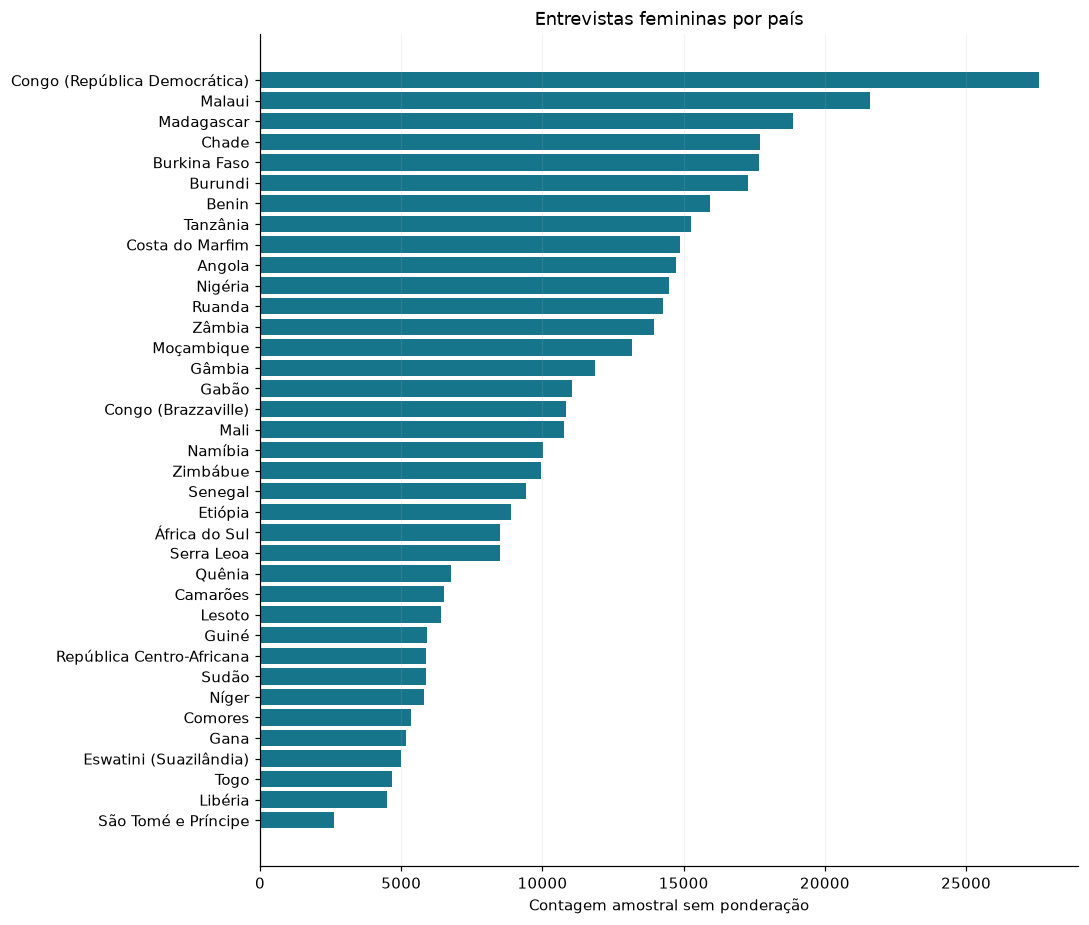

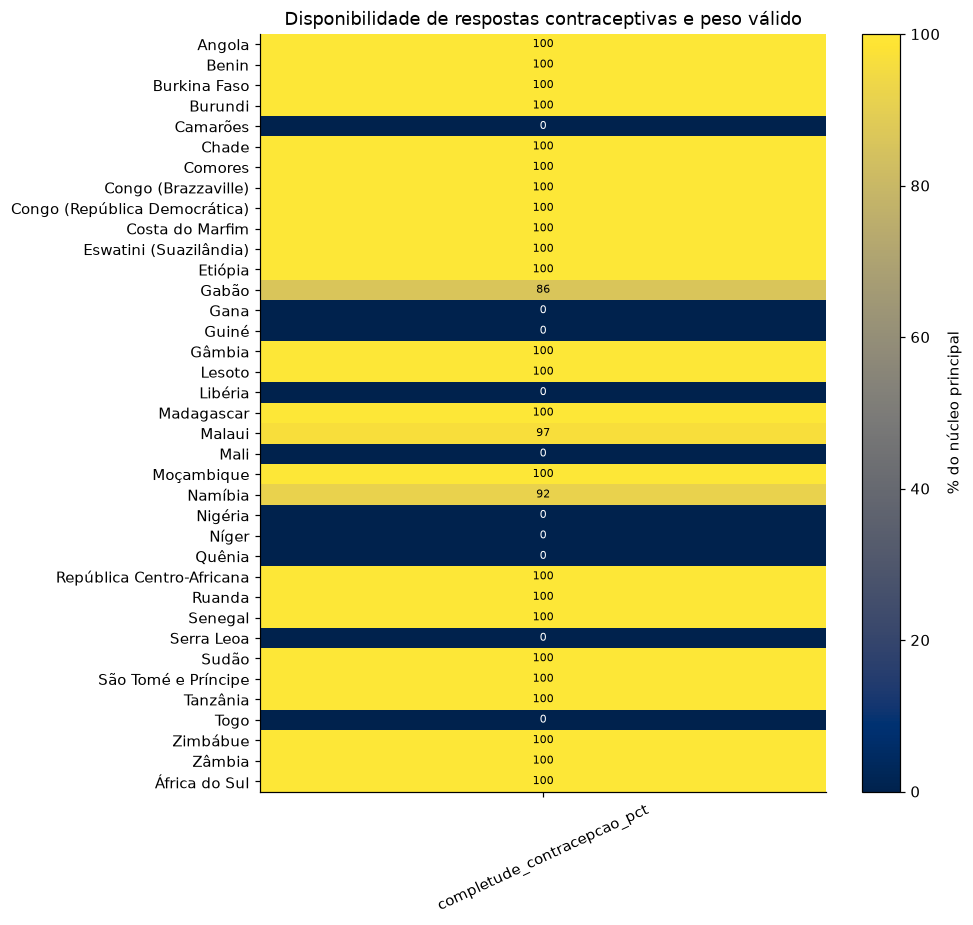

Foram analisadas 407.600 mulheres de 37 pesquisas. Há 331.364 entrevistas com resposta e peso válidos para analisar contracepção. As pesquisas vão de 1989 a 2025.

In [6]:
cobertura = consulta("""
SELECT p.codigo, p.nome, l.fase, MIN(e.ano) AS ano_min, MAX(e.ano) AS ano_max,
       COUNT(*) AS mulheres,
       SUM(e.usa_metodo IS NOT NULL AND e.peso>0) AS contracepcao_valida,
       ROUND(100.0*SUM(e.usa_metodo IS NOT NULL AND e.peso>0)/COUNT(*),2) AS completude_contracepcao_pct,
       SUM(m.escolaridade IS NULL) AS escolaridade_ausente,
       SUM(d.residencia IS NULL) AS residencia_ausente,
       SUM(d.riqueza IS NULL) AS riqueza_ausente,
       SUM(d.origem='HR') AS mulheres_com_HR
FROM Entrevista e JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id JOIN Pais p ON p.codigo=l.pais_codigo
GROUP BY p.codigo,p.nome,l.id,l.fase ORDER BY p.nome
""")
barras(cobertura.set_index('nome').mulheres, 'Entrevistas femininas por país', 'Contagem amostral sem ponderação')
mapa(cobertura.set_index('nome')[['completude_contracepcao_pct']],
     'Disponibilidade de respostas contraceptivas e peso válido', '% do núcleo principal')
display(Markdown(
    f"Foram analisadas {int(cobertura.mulheres.sum()):,} mulheres de {len(cobertura)} pesquisas. "
    f"Há {int(cobertura.contracepcao_valida.sum()):,} entrevistas com resposta e peso válidos para analisar contracepção. "
    f"As pesquisas vão de {int(cobertura.ano_min.min())} a {int(cobertura.ano_max.max())}."
))


```sql
SELECT 'Idade feminina fora de 15–49' AS verificacao, COUNT(*) AS registros
FROM Mulher WHERE idade IS NOT NULL AND idade NOT BETWEEN 15 AND 49
UNION ALL SELECT 'Peso feminino ausente', COUNT(*) FROM Entrevista WHERE peso IS NULL
UNION ALL SELECT 'Domicílios reconstruídos sem HR', COUNT(*) FROM Domicilio WHERE origem!='HR'
UNION ALL SELECT 'Nascimentos KR acrescentados sem BR', COUNT(*) FROM Nascimento WHERE origem='KR_sem_BR'
UNION ALL SELECT 'Respostas vacinais especiais (fora de 0–3)', COUNT(*) FROM Crianca_Vacina WHERE status_codigo NOT BETWEEN 0 AND 3
```

,verificacao,registros
0,Idade feminina fora de 15–49,2378
1,Peso feminino ausente,1580
2,Domicílios reconstruídos sem HR,71728
3,Nascimentos KR acrescentados sem BR,53333
4,Respostas vacinais especiais (fora de 0–3),7285


5 linhas no resultado completo; até 15 exibidas.


```sql
SELECT origem, COUNT(*) AS domicilios FROM Domicilio GROUP BY origem
```

,origem,domicilios
0,HR,385457
1,IR_sem_HR,5189
2,MR_sem_HR,66539


3 linhas no resultado completo; até 15 exibidas.


```sql
SELECT idade, COUNT(*) AS mulheres FROM Mulher GROUP BY idade ORDER BY idade
```

,idade,mulheres
0,15,18615
1,16,17589
2,17,16971
3,18,18752
4,19,15500
5,20,19433
6,21,13471
7,22,14526
8,23,14418
9,24,12994


50 linhas no resultado completo; até 15 exibidas.


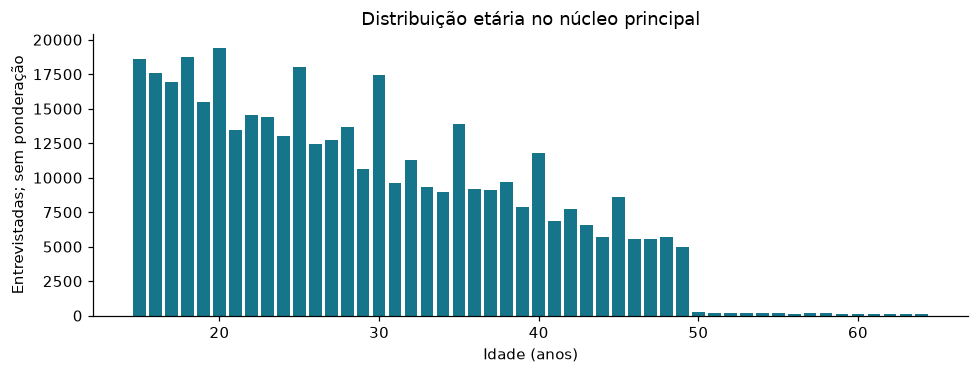

O número de entrevistas varia entre os países. Respostas em branco não são tratadas como respostas negativas.

In [ ]:
qualidade = consulta("""
SELECT 'Idade feminina fora de 15–49' AS verificacao, COUNT(*) AS registros
FROM Mulher WHERE idade IS NOT NULL AND idade NOT BETWEEN 15 AND 49
UNION ALL SELECT 'Peso feminino ausente', COUNT(*) FROM Entrevista WHERE peso IS NULL
UNION ALL SELECT 'Domicílios reconstruídos sem HR', COUNT(*) FROM Domicilio WHERE origem!='HR'
UNION ALL SELECT 'Nascimentos KR acrescentados sem BR', COUNT(*) FROM Nascimento WHERE origem='KR_sem_BR'
UNION ALL SELECT 'Respostas vacinais especiais (fora de 0–3)', COUNT(*) FROM Crianca_Vacina WHERE status_codigo NOT BETWEEN 0 AND 3
""")
domicilios_origem = consulta('SELECT origem, COUNT(*) AS domicilios FROM Domicilio GROUP BY origem')
idade = consulta('SELECT idade, COUNT(*) AS mulheres FROM Mulher GROUP BY idade ORDER BY idade')
fig, ax = plt.subplots(figsize=(9,3.5))
ax.bar(idade.idade, idade.mulheres, color='#964B00')
ax.set(xlabel='Idade (anos)', ylabel='Entrevistadas; sem ponderação', title='Distribuição etária no núcleo principal')
exibir(fig)
display(Markdown('O número de entrevistas varia entre os países. Respostas em branco não são tratadas como respostas negativas.'))


### 4.1 Informações que faltam

Os arquivos selecionados não têm informações para identificar mulheres com deficiência. Por isso, não foi possível fazer essa comparação.

In [8]:
esquemas = pd.read_csv(manifesto_path, dtype=str)
variaveis_deficiencia = sorted({v for lista in esquemas.colunas for v in lista.split('|')
                              if v.lower().startswith(('hdis', 'vdis', 'sdis'))})
display(pd.DataFrame([{'variaveis_funcionais_hdis_vdis_sdis': len(variaveis_deficiencia),
                       'recorte_deficiencia_observavel': bool(variaveis_deficiencia)}]))
assert variaveis_deficiencia == [], 'Reavaliar a cobertura se novas variáveis forem adicionadas.'

,variaveis_funcionais_hdis_vdis_sdis,recorte_deficiencia_observavel
0,0,False


## 5. Consultas

As dez consultas seguem os temas dos outros notebooks. Mostramos até 15 linhas de cada resultado. Os resultados completos ficam nas variáveis r1 a r10.

### Consulta 1: Adolescentes sem escolaridade

Selecionamos as mulheres de 15 a 19 anos que não têm escolaridade e contamos quantas aparecem em cada país.

```sql
SELECT substr(id,1,2) AS pais_codigo, id AS mulher_id, idade, idade_primeiro_nascimento, filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15 AND 19
  AND escolaridade = 0
ORDER BY id
```

,pais_codigo,mulher_id,idade,idade_primeiro_nascimento,filhos_nascidos_vivos
0,AO,AO_81|100|13|4,18,NaN,0
1,AO,AO_81|101|11|1,19,16.0,1
2,AO,AO_81|102|16|9,16,NaN,0
3,AO,AO_81|102|19|6,16,NaN,0
4,AO,AO_81|102|2|5,15,NaN,0
5,AO,AO_81|105|17|8,15,NaN,0
6,AO,AO_81|105|21|3,15,NaN,0
7,AO,AO_81|116|8|3,17,16.0,1
8,AO,AO_81|117|6|1,17,NaN,0
9,AO,AO_81|118|17|2,19,12.0,2


13,433 linhas no resultado completo; até 15 exibidas.


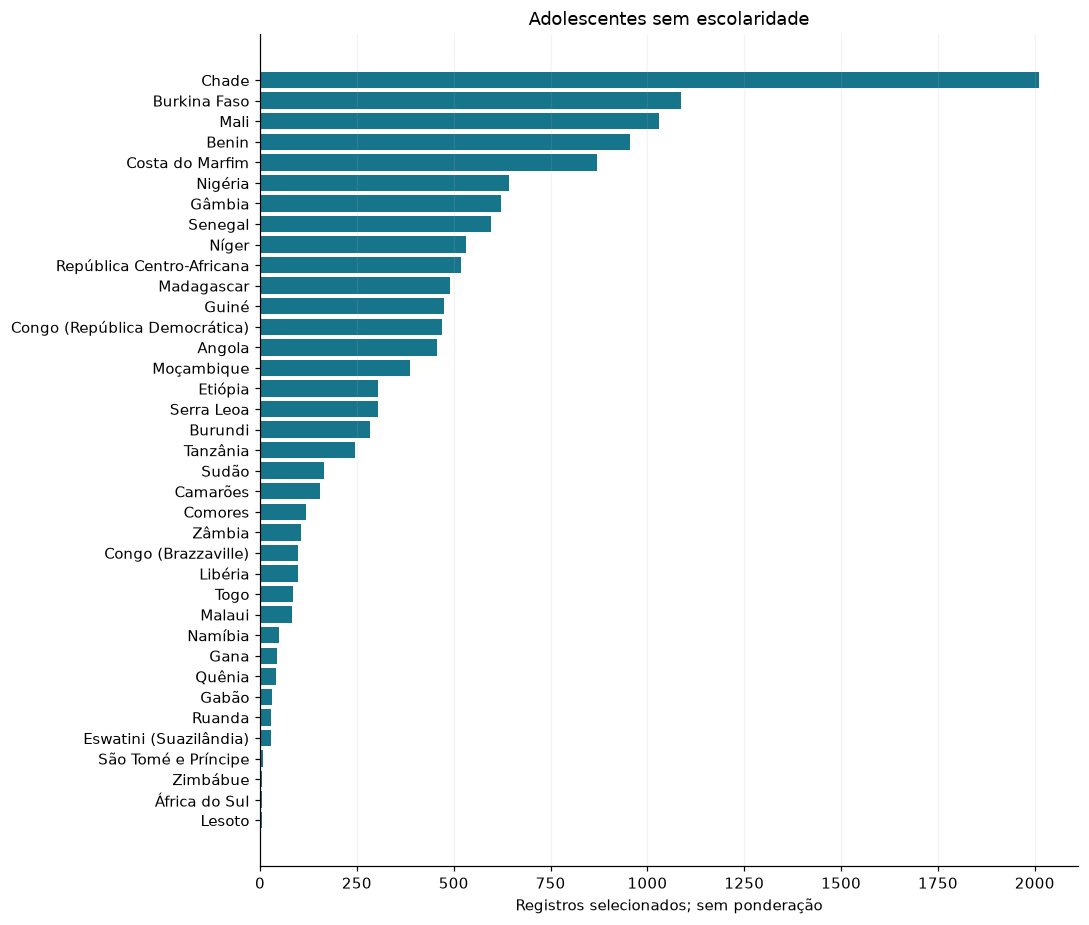

In [ ]:
sql_1 = """
SELECT substr(id,1,2) AS pais_codigo, id AS mulher_id, idade, idade_primeiro_nascimento, filhos_nascidos_vivos
FROM Mulher
WHERE idade BETWEEN 15 AND 19
  AND escolaridade = 0
ORDER BY id
"""
r1 = consulta(sql_1)
barras(r1.groupby('pais_codigo').size().rename(index=nomes), 'Adolescentes sem escolaridade', 'Registros selecionados; sem ponderação')

### Consulta 2: Domicílios rurais sem eletricidade

Selecionamos os domicílios rurais que estão entre os 20% mais pobres de cada país e não têm eletricidade.

```sql
SELECT substr(id,1,2) AS pais_codigo, id AS domicilio_id, fonte_agua, membros
FROM Domicilio
WHERE residencia = 2
  AND riqueza = 1
  AND eletricidade = 0
ORDER BY id
```

,pais_codigo,domicilio_id,fonte_agua,membros
0,AO,AO_81|101|17,43.0,2
1,AO,AO_81|101|2,43.0,7
2,AO,AO_81|101|22,43.0,1
3,AO,AO_81|101|4,43.0,2
4,AO,AO_81|105|16,31.0,1
5,AO,AO_81|105|17,32.0,9
6,AO,AO_81|105|9,32.0,1
7,AO,AO_81|107|1,14.0,8
8,AO,AO_81|107|11,42.0,3
9,AO,AO_81|107|12,14.0,1


75,029 linhas no resultado completo; até 15 exibidas.


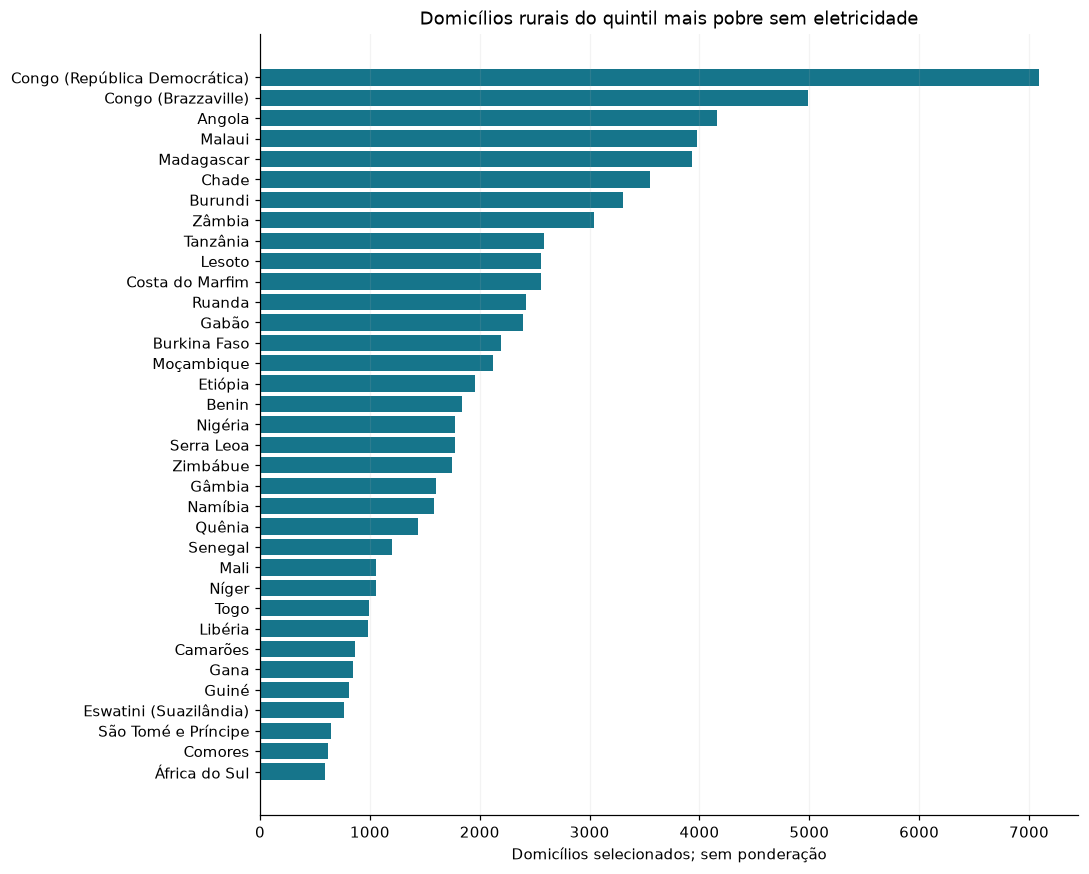

In [10]:
sql_2 = """
SELECT substr(id,1,2) AS pais_codigo, id AS domicilio_id, fonte_agua, membros
FROM Domicilio
WHERE residencia = 2
  AND riqueza = 1
  AND eletricidade = 0
ORDER BY id
"""
r2 = consulta(sql_2)
barras(r2.groupby('pais_codigo').size().rename(index=nomes), 'Domicílios rurais do quintil mais pobre sem eletricidade', 'Domicílios selecionados; sem ponderação')

### Consulta 3: Perfil das mulheres por local de moradia

Comparamos idade, número de filhos e escolaridade entre as mulheres das áreas urbanas e rurais de cada país.

```sql
SELECT substr(d.id,1,2) AS pais_codigo,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       ROUND(AVG(m.idade),2) AS idade_media,
       ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
       ROUND(100.0*AVG(m.escolaridade=0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
WHERE d.origem != 'IR_completo'
  AND d.residencia IN (1, 2)
GROUP BY pais_codigo, d.residencia
ORDER BY pais_codigo, d.residencia
```

,pais_codigo,residencia,mulheres,idade_media,filhos_medios,percentual_sem_escola
0,AO,Urbano,9066,26.87,2.19,10.07
1,AO,Rural,5651,27.99,3.17,40.93
2,BF,Urbano,6227,27.98,2.01,36.29
3,BF,Rural,11432,29.23,3.17,69.93
4,BJ,Urbano,7045,28.59,2.51,42.60
5,BJ,Rural,8883,28.46,3.17,64.85
6,BU,Urbano,3671,27.20,1.94,13.38
7,BU,Rural,13598,28.41,2.82,39.62
8,CD,Urbano,9146,27.41,2.30,5.18
9,CD,Rural,18437,28.40,3.25,23.77


72 linhas no resultado completo; até 15 exibidas.


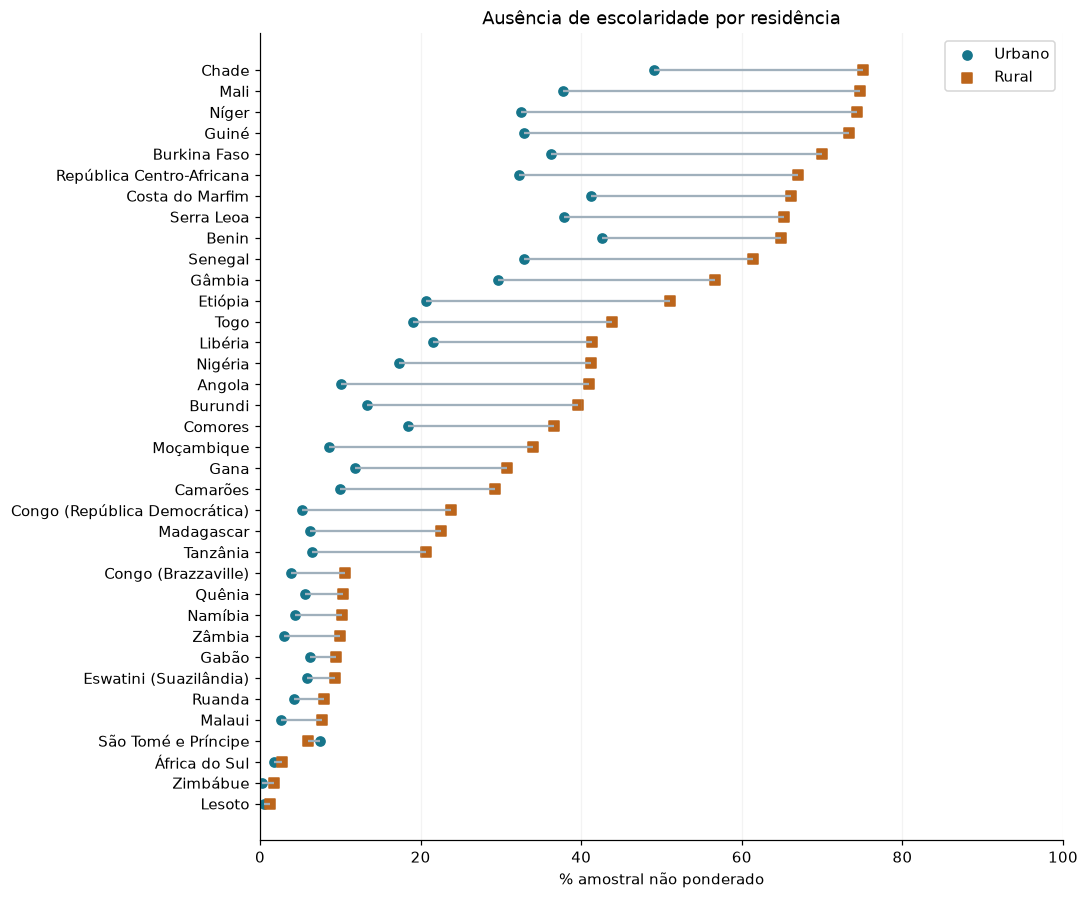

In [11]:
sql_3 = """
SELECT substr(d.id,1,2) AS pais_codigo,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       ROUND(AVG(m.idade),2) AS idade_media,
       ROUND(AVG(m.filhos_nascidos_vivos),2) AS filhos_medios,
       ROUND(100.0*AVG(m.escolaridade=0),2) AS percentual_sem_escola
FROM Mulher m
JOIN Domicilio d ON d.id = m.domicilio_id
WHERE d.origem != 'IR_completo'
  AND d.residencia IN (1, 2)
GROUP BY pais_codigo, d.residencia
ORDER BY pais_codigo, d.residencia
"""
r3 = consulta(sql_3)
pares(r3.pivot(index='pais_codigo', columns='residencia', values='percentual_sem_escola').rename(index=nomes), 'Urbano', 'Rural', 'Ausência de escolaridade por residência', '% amostral não ponderado')

### Consulta 4: Contracepção e escolaridade

Comparamos o uso de contraceptivos entre os níveis de escolaridade. O cálculo considera as respostas válidas e o peso das entrevistas.

```sql
SELECT substr(m.id,1,2) AS pais_codigo, m.escolaridade,
       COUNT(*) AS respostas_validas,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND m.escolaridade IS NOT NULL
GROUP BY pais_codigo, m.escolaridade
ORDER BY pais_codigo, m.escolaridade
```

,pais_codigo,escolaridade,respostas_validas,percentual_uso_ponderado
0,AO,0,3226,5.31
1,AO,1,4149,10.82
2,AO,2,6747,20.30
3,AO,3,595,28.28
4,BF,0,10254,29.04
5,BF,1,2515,31.30
6,BF,2,4548,30.46
7,BF,3,342,43.92
8,BJ,0,8762,12.42
9,BJ,1,3116,14.57


108 linhas no resultado completo; até 15 exibidas.


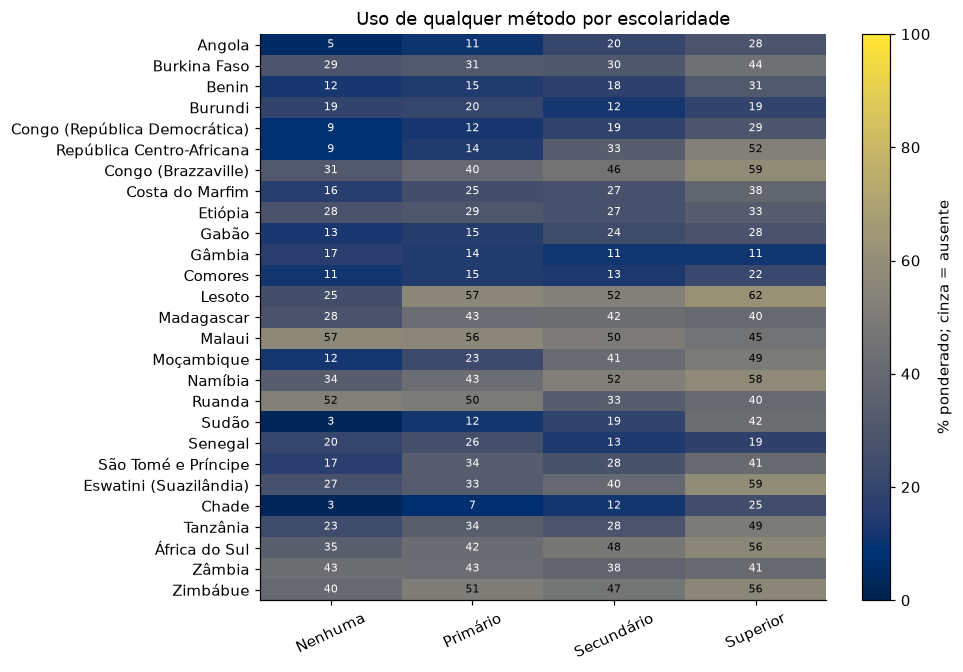

In [12]:
sql_4 = """
SELECT substr(m.id,1,2) AS pais_codigo, m.escolaridade,
       COUNT(*) AS respostas_validas,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS percentual_uso_ponderado
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND m.escolaridade IS NOT NULL
GROUP BY pais_codigo, m.escolaridade
ORDER BY pais_codigo, m.escolaridade
"""
r4 = consulta(sql_4)
mapa(r4.pivot(index='pais_codigo', columns='escolaridade', values='percentual_uso_ponderado').rename(index=nomes, columns={0:'Nenhuma',1:'Primário',2:'Secundário',3:'Superior'}), 'Uso de qualquer método por escolaridade', '% ponderado; cinza = ausente')

### Consulta 5: Conhecimento dos métodos contraceptivos

Verificamos quantas mulheres conhecem cada um dos nove métodos. O código 0 indica que a mulher não conhece o método. As respostas de 0 a 3 entram no cálculo, sem usar os pesos das entrevistas.

```sql
SELECT substr(k.mulher_id,1,2) AS pais_codigo,
       substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,
       t.nome, t.classe,
       COUNT(*) AS respostas_validas,
       SUM(k.nivel > 0) AS conhecem,
       ROUND(100.0*AVG(k.nivel > 0),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id = k.metodo_id
WHERE k.nivel BETWEEN 0 AND 3
GROUP BY pais_codigo, levantamento, t.id
ORDER BY pais_codigo, t.id
```

,pais_codigo,levantamento,nome,classe,respostas_validas,conhecem,percentual_conhecimento
0,AO,AO_81,Pílula,Moderno,14717,9755,66.28
1,AO,AO_81,DIU,Moderno,14717,5486,37.28
2,AO,AO_81,Injetáveis,Moderno,14717,9511,64.63
3,AO,AO_81,Preservativo masculino,Moderno,14717,11692,79.45
4,AO,AO_81,Esterilização feminina,Moderno,14717,3215,21.85
5,AO,AO_81,Esterilização masculina,Moderno,14717,2307,15.68
6,AO,AO_81,Abstinência periódica,Tradicional,14717,4959,33.70
7,AO,AO_81,Coito interrompido,Tradicional,14717,5447,37.01
8,BF,BF_81,Pílula,Moderno,17659,15830,89.64
9,BF,BF_81,DIU,Moderno,17659,10978,62.17


220 linhas no resultado completo; até 15 exibidas.


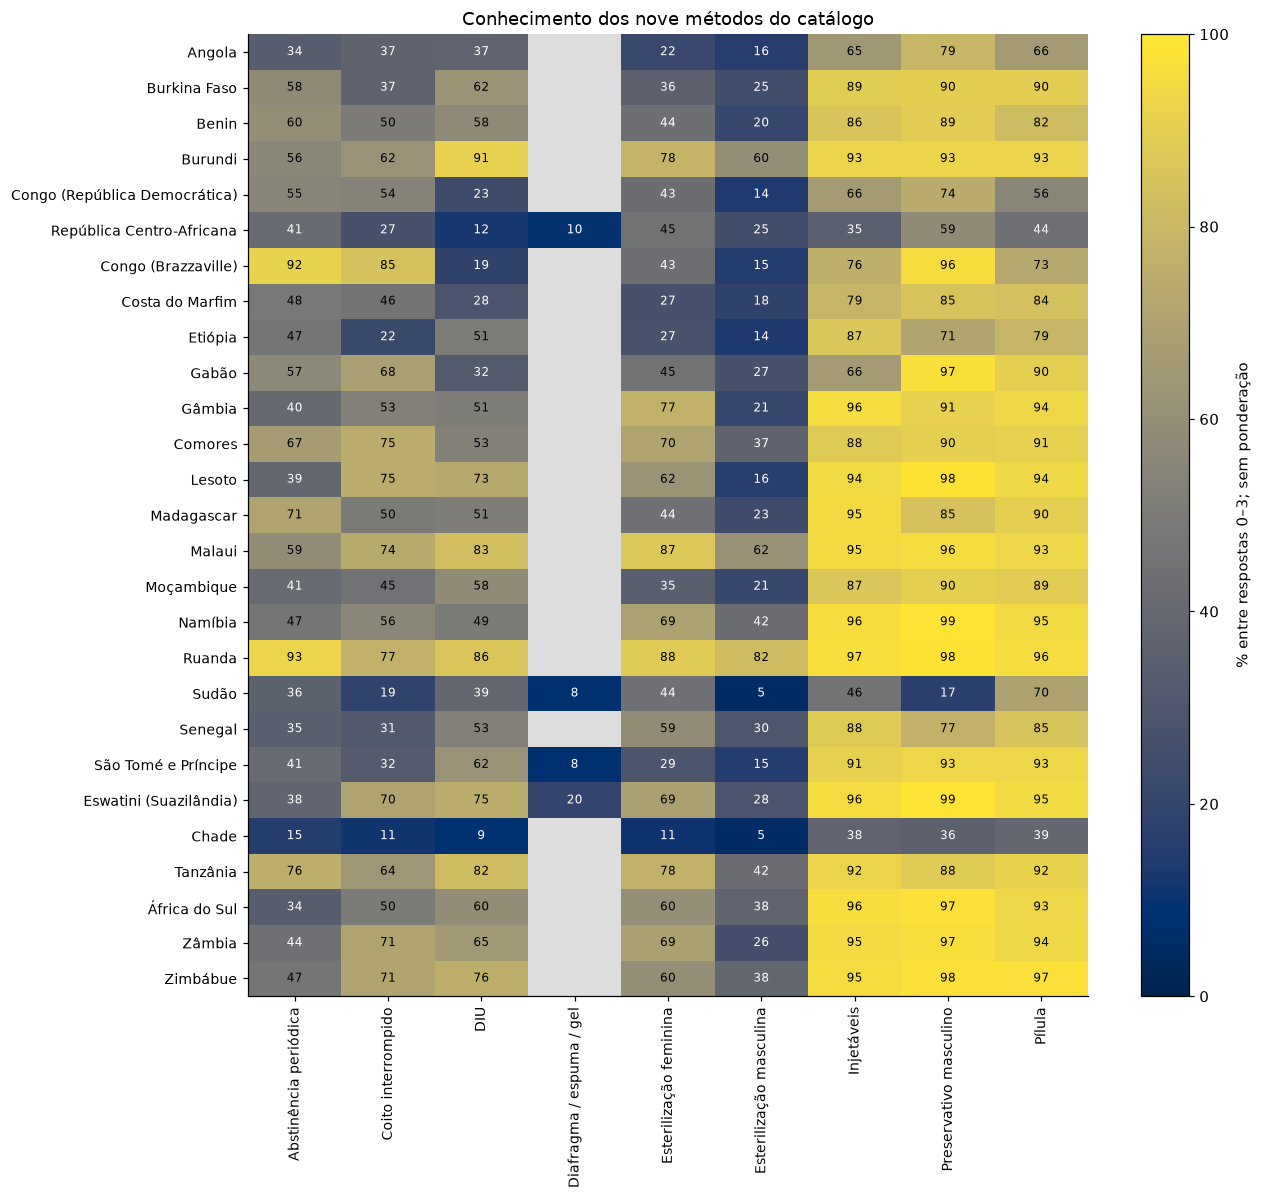

In [3]:
sql_5 = """
SELECT substr(k.mulher_id,1,2) AS pais_codigo,
       substr(k.mulher_id,1,instr(k.mulher_id,'|')-1) AS levantamento,
       t.nome, t.classe,
       COUNT(*) AS respostas_validas,
       SUM(k.nivel > 0) AS conhecem,
       ROUND(100.0*AVG(k.nivel > 0),2) AS percentual_conhecimento
FROM Conhecimento_Metodo k
JOIN Metodo t ON t.id = k.metodo_id
WHERE k.nivel BETWEEN 0 AND 3
GROUP BY pais_codigo, levantamento, t.id
ORDER BY pais_codigo, t.id
"""
r5 = consulta(sql_5)
visual = r5.pivot(index='pais_codigo', columns='nome', values='percentual_conhecimento').rename(index=nomes)
fig, ax = plt.subplots(figsize=(12, 11))
cmap = plt.get_cmap('cividis').copy()
cmap.set_bad('#dddddd')
im = ax.imshow(visual.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap=cmap)
ax.set_yticks(range(len(visual)), visual.index)
ax.set_xticks(range(len(visual.columns)), visual.columns, rotation=90)
ax.tick_params(axis='both', labelsize=9)
ax.set_title('Conhecimento dos nove métodos do catálogo')
for linha in range(len(visual)):
    for coluna in range(len(visual.columns)):
        valor = visual.iloc[linha, coluna]
        if pd.notna(valor):
            ax.text(coluna, linha, f'{valor:.0f}', ha='center', va='center',
                    fontsize=8, color='white' if valor<45 else 'black')
fig.colorbar(im, ax=ax, label='% entre respostas 0–3; sem ponderação')
exibir(fig)

### Consulta 6: Moradia e contexto familiar

Reunimos informações sobre riqueza, eletricidade, escolaridade e chefia do domicílio. Também comparamos dados das mulheres e dos homens entrevistados, sem considerar que eles formam casais.

In [ ]:
conn.executescript("""
DROP VIEW IF EXISTS temp.Parceiros_Area;
CREATE TEMP VIEW Parceiros_Area AS
SELECT l.pais_codigo AS codigo, d.residencia, COUNT(*) AS parceiros,
       ROUND(100.0*AVG(pr.escolaridade=0),2) AS parceiro_sem_escola_pct,
       ROUND(AVG(pr.idade_primeiro_filho),2) AS idade_1o_filho_parceiro
FROM Parceiro pr
JOIN Domicilio d ON d.id=pr.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
WHERE d.residencia IN (1,2)
GROUP BY l.pais_codigo,d.residencia;
""");

In [ ]:
conn.executescript("""
DROP VIEW IF EXISTS temp.Chefia_Area;
CREATE TEMP VIEW Chefia_Area AS
SELECT l.pais_codigo AS codigo, d.residencia,
       ROUND(100.0*AVG(mo.sexo=2),2) AS chefia_feminina_pct
FROM Morador mo
JOIN Domicilio d ON d.id=mo.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
WHERE mo.relacao_chefe_codigo=1 AND mo.sexo IN (1,2) AND d.residencia IN (1,2)
GROUP BY l.pais_codigo,d.residencia;
""");

```sql
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       COALESCE(pa.parceiros, 0) AS parceiros_entrevistados,
       ROUND(100.0*AVG(d.riqueza=1),2) AS percentual_quintil_1,
       ROUND(100.0*AVG(d.eletricidade=0),2) AS percentual_sem_eletricidade,
       ROUND(100.0*AVG(m.escolaridade=0),2) AS percentual_sem_escola,
       pa.parceiro_sem_escola_pct,
       ROUND(AVG(m.idade_primeiro_nascimento),2) AS idade_1o_filho_mulher,
       pa.idade_1o_filho_parceiro,
       ca.chefia_feminina_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
LEFT JOIN Parceiros_Area pa ON pa.codigo = p.codigo AND pa.residencia = d.residencia
LEFT JOIN Chefia_Area ca ON ca.codigo = p.codigo AND ca.residencia = d.residencia
WHERE e.coorte != 'contracepcao'
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
```

,codigo,nome,residencia,mulheres,parceiros_entrevistados,percentual_quintil_1,percentual_sem_eletricidade,percentual_sem_escola,parceiro_sem_escola_pct,idade_1o_filho_mulher,idade_1o_filho_parceiro,chefia_feminina_pct
0,AO,Angola,Urbano,9066,4043,1.18,19.17,10.07,4.23,18.95,22.77,35.69
1,AO,Angola,Rural,5651,2561,52.45,87.65,40.93,19.17,18.74,22.06,37.63
2,BJ,Benin,Urbano,7045,3383,13.03,42.19,42.60,26.37,20.48,25.36,25.30
3,BJ,Benin,Rural,8883,4212,21.82,77.43,64.85,46.75,19.30,24.23,24.19
4,BF,Burkina Faso,Urbano,6227,2819,1.08,45.85,36.29,28.73,20.16,26.85,18.58
5,BF,Burkina Faso,Rural,11432,4901,24.51,93.19,69.93,60.27,19.11,25.20,10.69
6,BU,Burundi,Urbano,3671,1764,3.84,40.42,13.38,10.49,21.47,27.04,27.37
7,BU,Burundi,Rural,13598,5788,21.00,97.56,39.62,30.65,20.69,24.50,29.22
8,CM,Camarões,Urbano,3755,3702,2.45,12.52,9.99,6.05,NaN,26.02,28.90
9,CM,Camarões,Rural,2777,3276,35.22,64.60,29.28,14.13,NaN,24.65,24.01


72 linhas no resultado completo; até 15 exibidas.


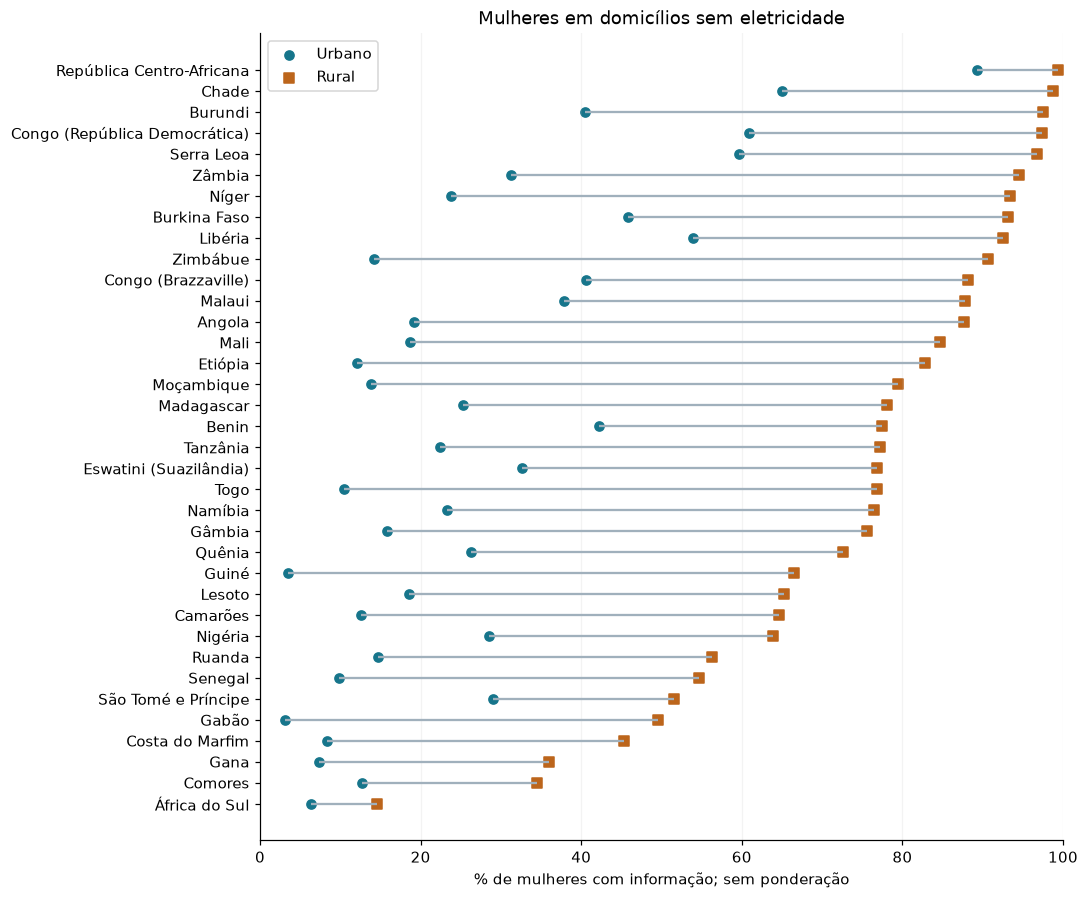

In [14]:
sql_6 = """
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS mulheres,
       COALESCE(pa.parceiros, 0) AS parceiros_entrevistados,
       ROUND(100.0*AVG(d.riqueza=1),2) AS percentual_quintil_1,
       ROUND(100.0*AVG(d.eletricidade=0),2) AS percentual_sem_eletricidade,
       ROUND(100.0*AVG(m.escolaridade=0),2) AS percentual_sem_escola,
       pa.parceiro_sem_escola_pct,
       ROUND(AVG(m.idade_primeiro_nascimento),2) AS idade_1o_filho_mulher,
       pa.idade_1o_filho_parceiro,
       ca.chefia_feminina_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
LEFT JOIN Parceiros_Area pa ON pa.codigo = p.codigo AND pa.residencia = d.residencia
LEFT JOIN Chefia_Area ca ON ca.codigo = p.codigo AND ca.residencia = d.residencia
WHERE e.coorte != 'contracepcao'
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
"""
r6 = consulta(sql_6)
pares(r6.pivot(index='nome', columns='residencia', values='percentual_sem_eletricidade'), 'Urbano', 'Rural', 'Mulheres em domicílios sem eletricidade', '% de mulheres com informação; sem ponderação')

### Consulta 7: Pré-natal e parto

Analisamos o último nascimento de cada mulher nos cinco anos anteriores à entrevista. Observamos as consultas de pré-natal, o local do parto e a ocorrência de cesárea. Os campos m3a e m3b informam sobre atendimento no pré-natal, não sobre assistência no parto. Seus códigos precisam ser conferidos em cada pesquisa.

```sql
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS nascimentos_recentes,
       COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END) AS respostas_validas,
       ROUND(100.0*COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END)/COUNT(*),2) AS cobertura_resposta_percentual,
       ROUND(100.0*AVG(CASE WHEN n.local_parto_codigo BETWEEN 10 AND 96
                       THEN n.local_parto_codigo BETWEEN 20 AND 49 END),2) AS local_parto_codigos_20_49_pct,
       ROUND(100.0*AVG(CASE
           WHEN n.assistencia_medico_codigo=1 OR n.assistencia_m3b_codigo=1 THEN 1
           WHEN n.assistencia_medico_codigo=0 AND n.assistencia_m3b_codigo=0 THEN 0
       END),2) AS relato_prenatal_medico_ou_m3b_pct,
       ROUND(100.0*AVG(CASE WHEN n.cesarea_codigo IN (0,1) THEN n.cesarea_codigo END),2) AS cesarea_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
```

,codigo,nome,residencia,nascimentos_recentes,respostas_validas,cobertura_resposta_percentual,local_parto_codigos_20_49_pct,relato_prenatal_medico_ou_m3b_pct,cesarea_pct
0,AO,Angola,Urbano,4208,2992,71.10,67.01,71.24,9.34
1,AO,Angola,Rural,3617,2865,79.21,22.78,25.40,2.36
2,BJ,Benin,Urbano,3628,3513,96.83,90.96,17.06,8.90
3,BJ,Benin,Rural,5349,5237,97.91,80.41,11.53,3.81
4,BF,Burkina Faso,Urbano,2777,1859,66.94,97.34,5.80,10.19
5,BF,Burkina Faso,Rural,6515,4525,69.46,92.97,2.31,4.86
6,BU,Burundi,Urbano,1478,1476,99.86,94.86,27.33,17.47
7,BU,Burundi,Rural,7161,7158,99.96,82.15,9.43,4.44
8,CM,Camarões,Urbano,1561,1122,71.88,NaN,NaN,NaN
9,CM,Camarões,Rural,1524,1202,78.87,NaN,NaN,NaN


72 linhas no resultado completo; até 15 exibidas.


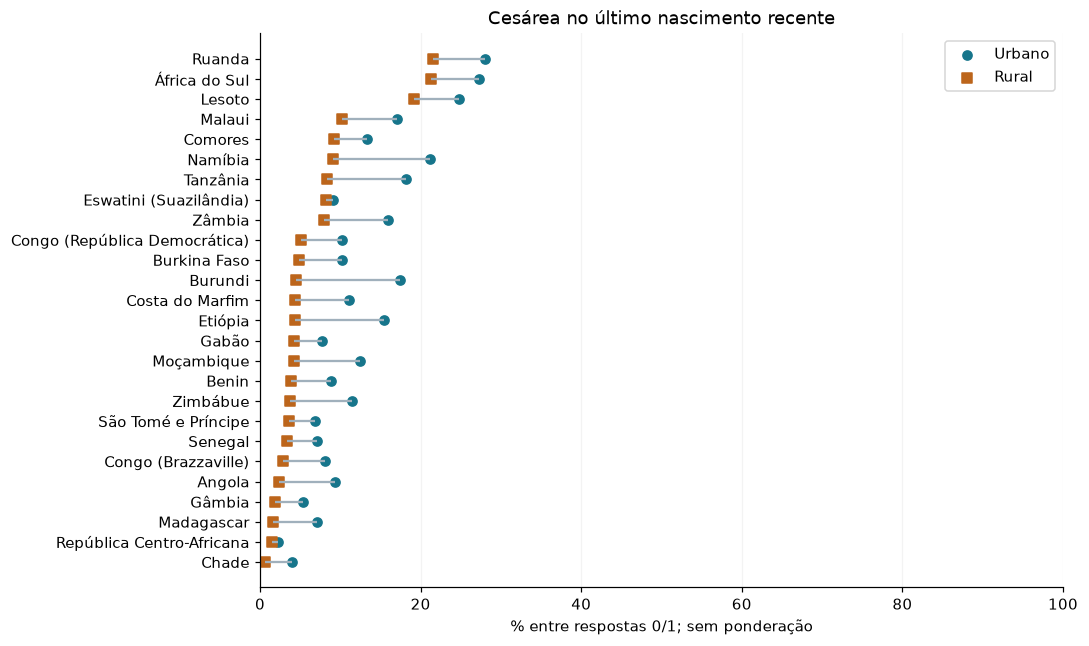

In [15]:
sql_7 = """
SELECT p.codigo, p.nome,
       CASE d.residencia WHEN 1 THEN 'Urbano' WHEN 2 THEN 'Rural' END AS residencia,
       COUNT(*) AS nascimentos_recentes,
       COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END) AS respostas_validas,
       ROUND(100.0*COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END)/COUNT(*),2) AS cobertura_resposta_percentual,
       ROUND(100.0*AVG(CASE WHEN n.local_parto_codigo BETWEEN 10 AND 96
                       THEN n.local_parto_codigo BETWEEN 20 AND 49 END),2) AS local_parto_codigos_20_49_pct,
       ROUND(100.0*AVG(CASE
           WHEN n.assistencia_medico_codigo=1 OR n.assistencia_m3b_codigo=1 THEN 1
           WHEN n.assistencia_medico_codigo=0 AND n.assistencia_m3b_codigo=0 THEN 0
       END),2) AS relato_prenatal_medico_ou_m3b_pct,
       ROUND(100.0*AVG(CASE WHEN n.cesarea_codigo IN (0,1) THEN n.cesarea_codigo END),2) AS cesarea_pct
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND d.residencia IN (1, 2)
GROUP BY p.codigo, p.nome, d.residencia
ORDER BY p.nome, d.residencia
"""
r7 = consulta(sql_7)
pares(r7.pivot(index='nome', columns='residencia', values='cesarea_pct'), 'Urbano', 'Rural', 'Cesárea no último nascimento recente', '% entre respostas 0/1; sem ponderação')

### Consulta 8: Contracepção e vacinação infantil

Mostramos o conhecimento e o uso de contraceptivos entre as mulheres, junto com a vacinação de crianças de 12 a 23 meses. São grupos diferentes, e essa comparação não mostra que o uso de contraceptivos causa mudanças na vacinação. Respostas em branco ou com código 8 ou 9 ficam fora do cálculo das vacinas.

In [ ]:
conn.executescript("""
DROP VIEW IF EXISTS temp.Conhecimento_Moderno;
CREATE TEMP VIEW Conhecimento_Moderno AS
SELECT k.mulher_id,
       CASE WHEN MAX(k.nivel)>0 THEN 1 WHEN COUNT(*)=7 THEN 0 END AS conhece_moderno
FROM Conhecimento_Metodo k JOIN Metodo t ON t.id=k.metodo_id
WHERE t.classe='Moderno' AND k.nivel BETWEEN 0 AND 3
GROUP BY k.mulher_id;
""");

In [ ]:
conn.executescript("""
DROP VIEW IF EXISTS temp.Vacinacao_Pais;
CREATE TEMP VIEW Vacinacao_Pais AS
SELECT l.pais_codigo AS codigo,
       COUNT(DISTINCT c.nascimento_id) AS criancas_com_resposta,
       COUNT(*) AS respostas_vacinais_validas,
       ROUND(100.0*AVG(cv.status_codigo>0),2) AS registros_vacinais_positivos_pct,
       SUM(v.codigo='h9') AS respostas_sarampo,
       ROUND(100.0*AVG(CASE WHEN v.codigo='h9' THEN cv.status_codigo>0 END),2) AS sarampo_pct
FROM Crianca c
JOIN Nascimento n ON n.id=c.nascimento_id
JOIN Mulher m ON m.id=n.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Crianca_Vacina cv ON cv.nascimento_id=c.nascimento_id
JOIN Vacina_Remedio v ON v.id=cv.vacina_id
WHERE c.idade_anos=1 AND cv.status_codigo BETWEEN 0 AND 3
GROUP BY l.pais_codigo;
""");

In [ ]:
conn.executescript("""
DROP VIEW IF EXISTS temp.Contracepcao_Pais;
CREATE TEMP VIEW Contracepcao_Pais AS
SELECT l.pais_codigo AS codigo, COUNT(*) AS mulheres_respostas_validas,
       ROUND(100.0*SUM(e.peso*k.conhece_moderno)/SUM(e.peso),2) AS conhece_moderno_pct,
       ROUND(100.0*SUM(e.peso*e.usa_metodo)/SUM(e.peso),2) AS uso_qualquer_pct
FROM Entrevista e
JOIN Mulher m ON m.id=e.mulher_id
JOIN Domicilio d ON d.id=m.domicilio_id
JOIN Levantamento l ON l.id=d.levantamento_id
JOIN Conhecimento_Moderno k ON k.mulher_id=m.id
WHERE e.usa_metodo IS NOT NULL AND e.peso>0 AND k.conhece_moderno IS NOT NULL
GROUP BY l.pais_codigo;
""");

```sql
SELECT p.codigo,p.nome,w.mulheres_respostas_validas,w.conhece_moderno_pct,w.uso_qualquer_pct,
       v.criancas_com_resposta,v.respostas_vacinais_validas,
       v.registros_vacinais_positivos_pct,v.respostas_sarampo,v.sarampo_pct
FROM Pais p
LEFT JOIN Contracepcao_Pais w ON w.codigo=p.codigo
LEFT JOIN Vacinacao_Pais v ON v.codigo=p.codigo
ORDER BY p.nome
```

,codigo,nome,mulheres_respostas_validas,conhece_moderno_pct,uso_qualquer_pct,criancas_com_resposta,respostas_vacinais_validas,registros_vacinais_positivos_pct,respostas_sarampo,sarampo_pct
0,AO,Angola,11999.0,100.00,18.26,2068.0,16332.0,52.87,2020.0,47.18
1,BJ,Benin,14868.0,100.00,15.36,2521.0,20118.0,77.05,2507.0,68.25
2,BF,Burkina Faso,16877.0,100.00,31.47,2313.0,18437.0,90.87,2288.0,86.58
3,BU,Burundi,16735.0,100.00,18.43,2596.0,20764.0,96.73,2596.0,93.37
4,CM,Camarões,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,TD,Chade,8517.0,100.00,9.34,2877.0,22682.0,51.85,2837.0,53.15
6,KM,Comores,5127.0,100.00,14.23,630.0,4987.0,79.59,620.0,75.32
7,CG,Congo (Brazzaville),10509.0,100.00,45.12,1884.0,15021.0,70.42,1878.0,68.90
8,CD,Congo (República Democrática),22477.0,100.00,19.19,4206.0,33534.0,49.42,4180.0,48.73
9,CI,Costa do Marfim,13363.0,100.00,24.03,1920.0,15309.0,70.93,1905.0,65.14


37 linhas no resultado completo; até 15 exibidas.


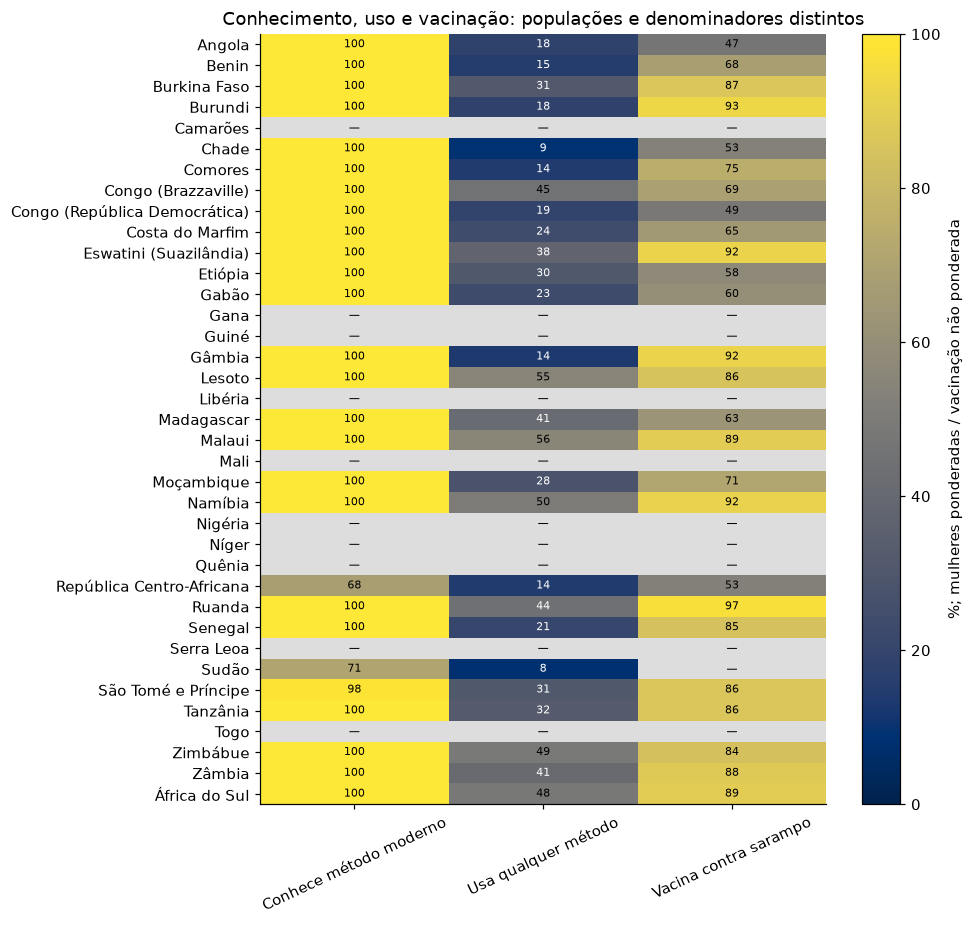

In [4]:
sql_8 = """
SELECT p.codigo,p.nome,w.mulheres_respostas_validas,w.conhece_moderno_pct,w.uso_qualquer_pct,
       v.criancas_com_resposta,v.respostas_vacinais_validas,
       v.registros_vacinais_positivos_pct,v.respostas_sarampo,v.sarampo_pct
FROM Pais p
LEFT JOIN Contracepcao_Pais w ON w.codigo=p.codigo
LEFT JOIN Vacinacao_Pais v ON v.codigo=p.codigo
ORDER BY p.nome
"""
r8 = consulta(sql_8)
mapa(r8.set_index('nome')[['conhece_moderno_pct','uso_qualquer_pct','sarampo_pct']].rename(columns={'conhece_moderno_pct':'Conhece método moderno','uso_qualquer_pct':'Usa qualquer método','sarampo_pct':'Vacina contra sarampo'}), 'Conhecimento, uso e vacinação: populações e denominadores distintos', '%; mulheres ponderadas / vacinação não ponderada')

### Consulta 9: Contracepção e condições de vida

Comparamos o uso de contraceptivos por riqueza, escolaridade e local de moradia, usando os pesos das entrevistas dentro de cada país.

```sql
SELECT p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade,
       COUNT(*) AS n,
       SUM(e.peso) AS peso_total,
       SUM(e.peso * e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
  AND m.escolaridade BETWEEN 0 AND 3
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade
ORDER BY p.nome, d.residencia, d.riqueza, m.escolaridade
```

,codigo,nome,residencia,riqueza,escolaridade,n,peso_total,peso_uso
0,AO,Angola,1,1,0,44,32.537380,0.379562
1,AO,Angola,1,1,1,37,34.691687,1.096992
2,AO,Angola,1,1,2,26,20.120082,2.879600
3,AO,Angola,1,2,0,284,210.090319,7.097133
4,AO,Angola,1,2,1,365,305.121579,15.571363
5,AO,Angola,1,2,2,281,233.272810,39.209519
6,AO,Angola,1,3,0,354,266.940714,17.497694
7,AO,Angola,1,3,1,813,774.803185,113.595157
8,AO,Angola,1,3,2,1523,1373.433466,252.920204
9,AO,Angola,1,3,3,23,13.033430,2.390045


917 linhas no resultado completo; até 15 exibidas.


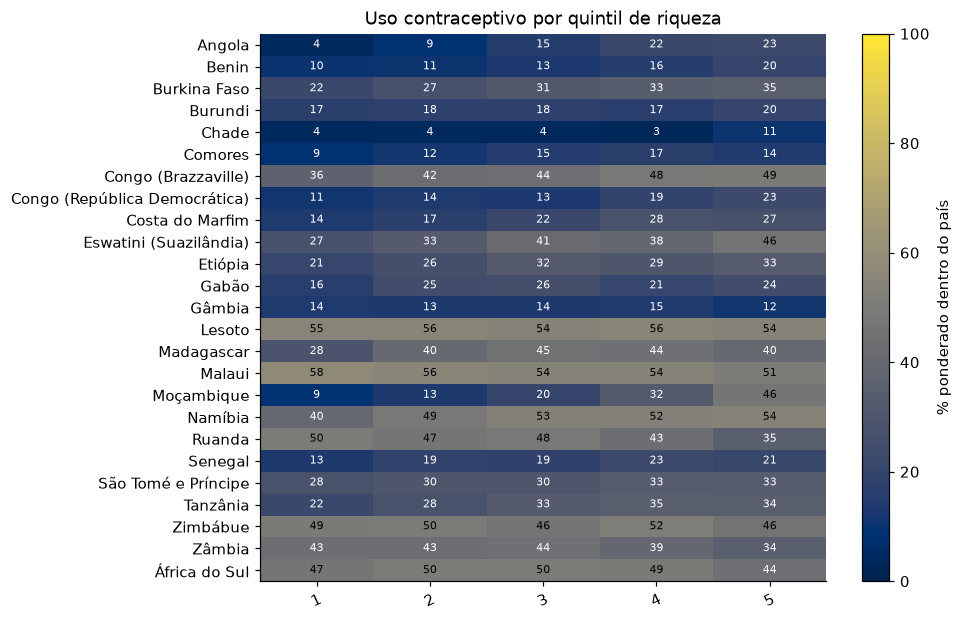

In [17]:
sql_9 = """
SELECT p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade,
       COUNT(*) AS n,
       SUM(e.peso) AS peso_total,
       SUM(e.peso * e.usa_metodo) AS peso_uso
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
WHERE e.coorte != 'nucleo_exclusivo'
  AND e.usa_metodo IS NOT NULL
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
  AND m.escolaridade BETWEEN 0 AND 3
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza, m.escolaridade
ORDER BY p.nome, d.residencia, d.riqueza, m.escolaridade
"""
r9 = consulta(sql_9)
por_riqueza = r9.groupby(['nome','riqueza'])[['peso_total','peso_uso']].sum()
por_riqueza['uso_pct'] = 100*por_riqueza.peso_uso/por_riqueza.peso_total
mapa(por_riqueza.uso_pct.unstack(), 'Uso contraceptivo por quintil de riqueza', '% ponderado dentro do país')

### Consulta 10: Número de consultas de pré-natal

Comparamos a proporção de mulheres que fizeram quatro ou mais consultas de pré-natal, por riqueza e local de moradia. Consideramos o último nascimento nos cinco anos anteriores à entrevista. Esse número de consultas foi escolhido para a comparação e não define, por si só, um atendimento adequado.

```sql
SELECT p.codigo, p.nome, d.residencia, d.riqueza,
       COUNT(*) AS nascimentos_recentes,
       COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END) AS n_validos,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4 AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza
ORDER BY p.nome, d.residencia, d.riqueza
```

,codigo,nome,residencia,riqueza,nascimentos_recentes,n_validos,peso_valido,peso_quatro_mais
0,AO,Angola,1,1,66,50,38.705283,14.212405
1,AO,Angola,1,2,558,425,338.977883,144.427086
2,AO,Angola,1,3,1537,1127,974.057613,618.625296
3,AO,Angola,1,4,1174,795,870.177007,702.901841
4,AO,Angola,1,5,873,595,710.826592,649.617429
5,AO,Angola,2,1,1946,1548,1229.179719,312.428171
6,AO,Angola,2,2,1245,993,967.351867,360.262453
7,AO,Angola,2,3,336,260,201.882627,116.874049
8,AO,Angola,2,4,60,46,36.156285,25.425303
9,AO,Angola,2,5,30,18,12.173921,11.714798


344 linhas no resultado completo; até 15 exibidas.


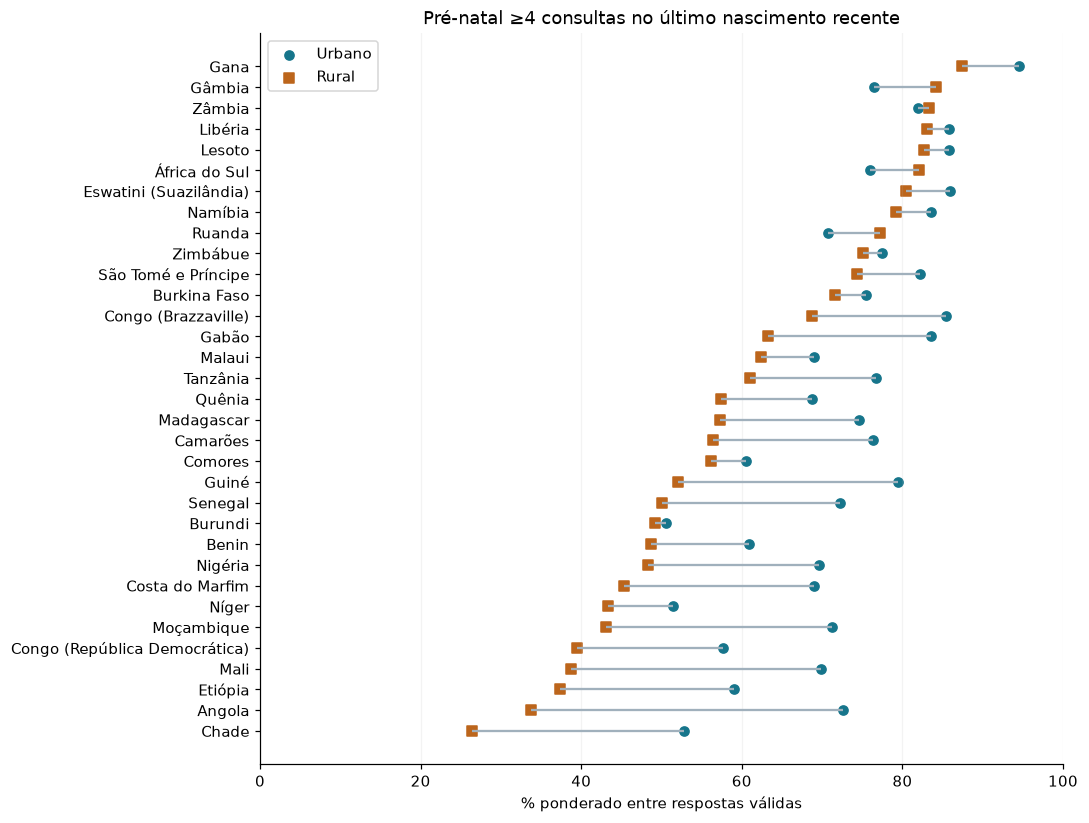

In [18]:
sql_10 = """
SELECT p.codigo, p.nome, d.residencia, d.riqueza,
       COUNT(*) AS nascimentos_recentes,
       COUNT(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN 1 END) AS n_validos,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 0 AND 90 THEN e.peso ELSE 0 END) AS peso_valido,
       SUM(CASE WHEN n.consultas_prenatal_codigo BETWEEN 4 AND 90 THEN e.peso ELSE 0 END) AS peso_quatro_mais
FROM Entrevista e
JOIN Mulher m ON m.id = e.mulher_id
JOIN Domicilio d ON d.id = m.domicilio_id
JOIN Levantamento l ON l.id = d.levantamento_id
JOIN Pais p ON p.codigo = l.pais_codigo
JOIN Nascimento n ON n.mulher_id = m.id
WHERE n.indice = 1
  AND e.data_cmc - n.data_cmc BETWEEN 0 AND 59
  AND e.peso > 0
  AND d.residencia IN (1, 2)
  AND d.riqueza BETWEEN 1 AND 5
GROUP BY p.codigo, p.nome, d.residencia, d.riqueza
ORDER BY p.nome, d.residencia, d.riqueza
"""
r10 = consulta(sql_10)
por_area = r10.groupby(['nome','residencia'])[['peso_valido','peso_quatro_mais']].sum()
por_area['prenatal_pct'] = 100*por_area.peso_quatro_mais/por_area.peso_valido.replace(0,np.nan)
pares(por_area.prenatal_pct.unstack().rename(columns={1:'Urbano',2:'Rural'}), 'Urbano', 'Rural', 'Pré-natal ≥4 consultas no último nascimento recente', '% ponderado entre respostas válidas')

## 6. Comparando os resultados

As áreas urbanas e rurais têm diferenças de riqueza e escolaridade. Para comparar grupos mais parecidos, separamos as mulheres por essas duas características e usamos grupos com pelo menos 30 respostas em cada área. Repetimos a comparação com mínimos de 50 e 100 respostas para ver se o resultado mudava.

No mapa de pré-natal, os grupos com menos de 30 respostas válidas ficam em cinza. Falta de informação não significa percentual zero.

codigo,pais,estratos,bruta_pp,padronizada_pp,suporte_urbano_pct,suporte_rural_pct,inversao
ST,São Tomé e Príncipe,10,-8.59,-9.73,92.96,93.38,False
MD,Madagascar,15,-2.77,-6.96,98.91,95.87,False
ZM,Zâmbia,11,-7.62,-5.58,93.60,63.76,False
ET,Etiópia,11,2.00,-3.90,94.09,73.05,True
AO,Angola,10,11.47,-3.43,79.43,94.56,True
RW,Ruanda,15,-8.57,-2.89,98.84,99.20,False
CI,Costa do Marfim,14,5.86,-2.65,84.91,98.98,True
MZ,Moçambique,12,17.88,-2.21,97.17,84.87,True
CG,Congo (Brazzaville),7,2.04,-1.30,85.02,44.72,True
BU,Burundi,11,1.57,-0.25,89.95,81.21,True


Países com poucas respostas para esta comparação: CF, CM, GH, GN, KE, LB, ML, NG, NI, SD, SL, TG


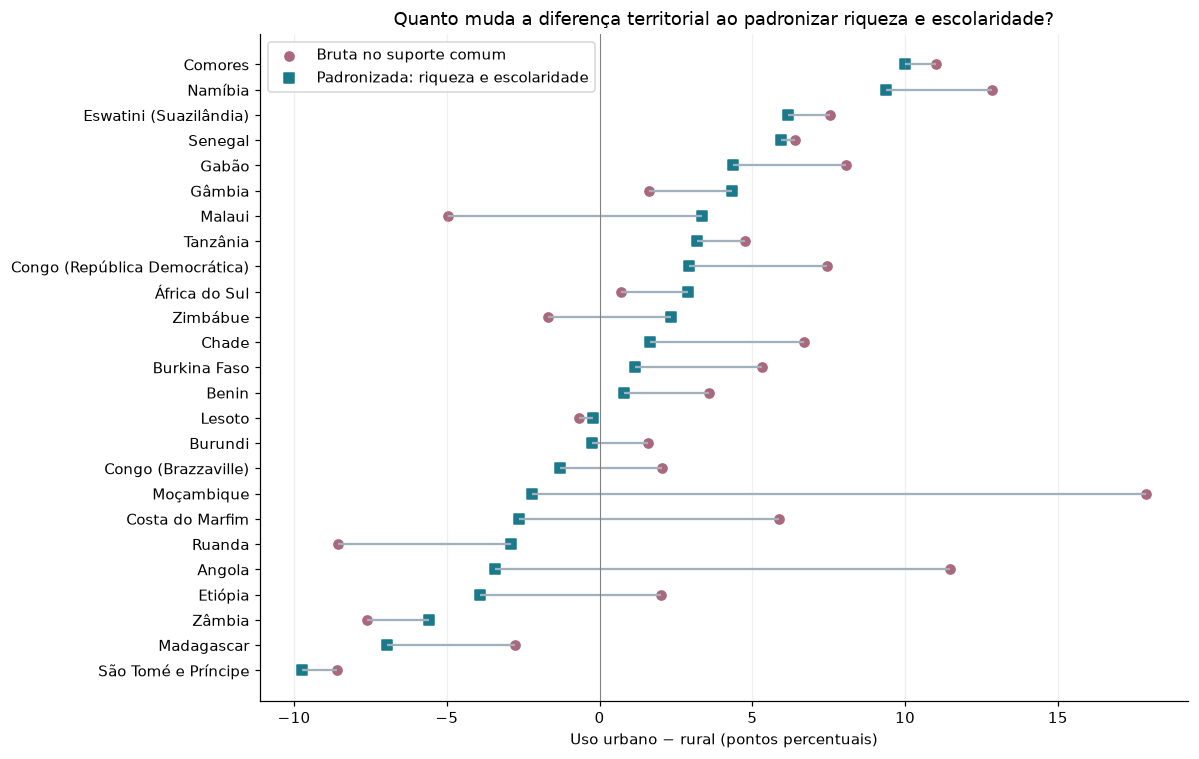

Foi possível comparar 25 países. Após considerar riqueza e escolaridade, o uso de contraceptivos foi maior na área urbana em 14 deles. Em 8, a diferença mudou de sentido. As maiores mudanças ocorreram em Moçambique, Angola, Costa do Marfim.

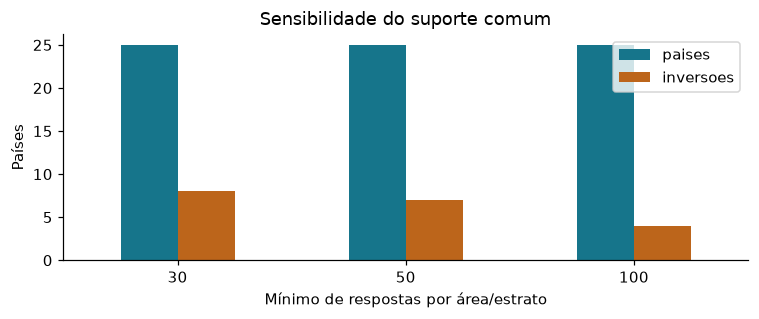

codigo,pais,minimo_por_area,estratos,bruta_pp,padronizada_pp,inversao
AO,Angola,30,10,11.47,-3.43,True
BF,Burkina Faso,30,12,5.31,1.17,False
BJ,Benin,30,15,3.57,0.80,False
BU,Burundi,30,11,1.57,-0.25,True
CD,Congo (República Democrática),30,13,7.45,2.91,False
CG,Congo (Brazzaville),30,7,2.04,-1.30,True
CI,Costa do Marfim,30,14,5.86,-2.65,True
ET,Etiópia,30,11,2.00,-3.90,True
GA,Gabão,30,7,8.06,4.38,False
GM,Gâmbia,30,12,1.60,4.35,False


Ao repetir a comparação com pelo menos 30, 50 e 100 respostas em cada grupo, a inversão permaneceu em Congo (Brazzaville), Costa do Marfim, Malaui, Moçambique. Os grupos comparados variam conforme esse mínimo.

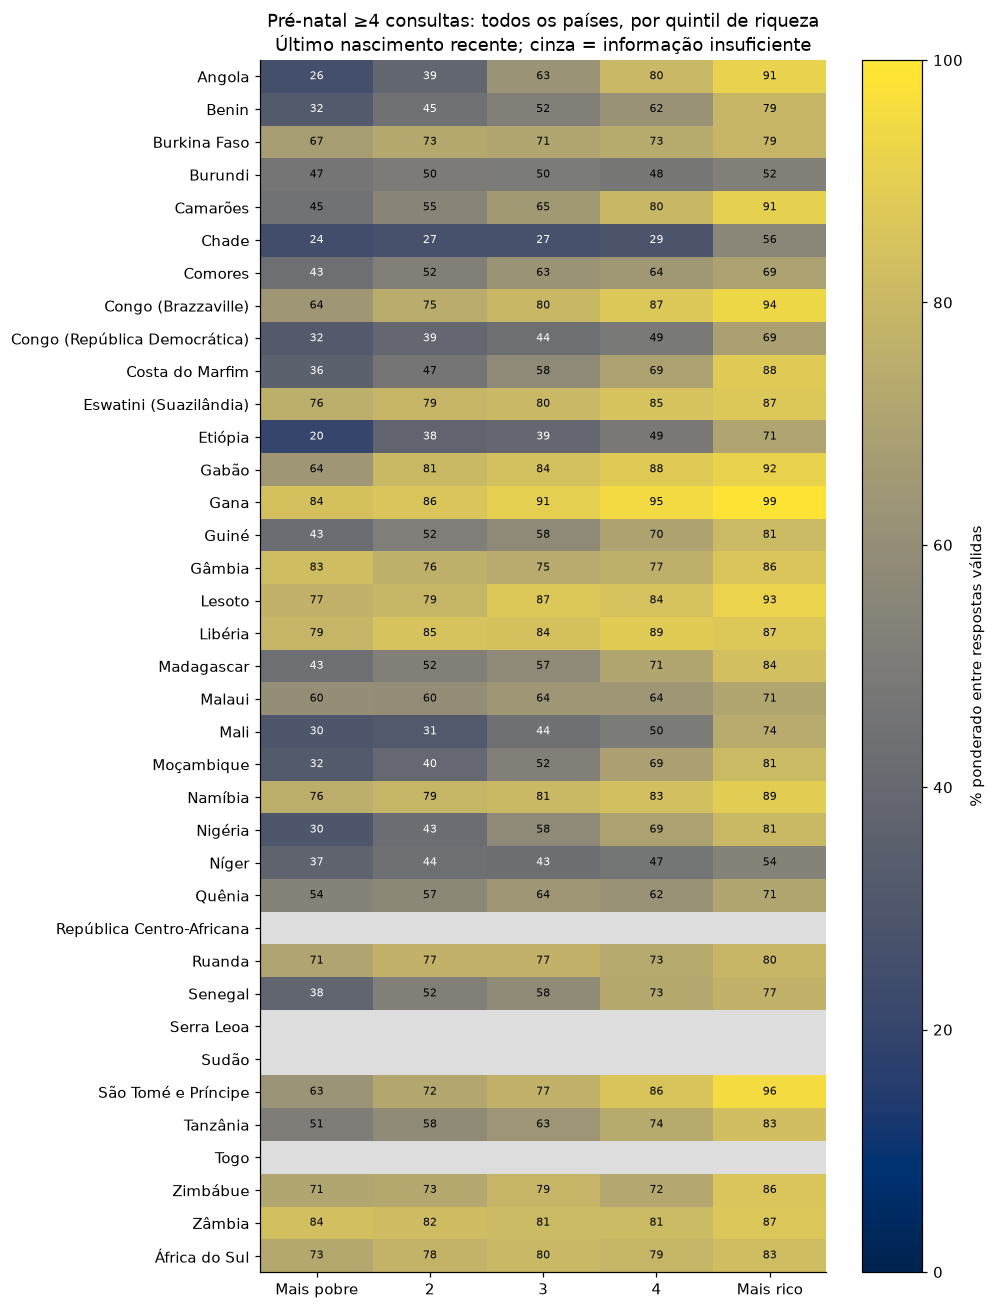

riqueza,nome,1,5,diferenca_pp
,Angola,25.76,91.47,65.71
,Benin,31.81,79.17,47.36
,Burkina Faso,67.28,79.17,11.88
,Burundi,47.07,52.18,5.11
,Camarões,45.29,90.94,45.64
,Chade,24.28,55.55,31.26
,Comores,43.42,69.46,26.04
,Congo (Brazzaville),64.05,93.71,29.66
,Congo (República Democrática),32.39,69.10,36.71
,Costa do Marfim,35.91,87.97,52.06


nome,n_validos,nascimentos_recentes,cobertura_pct
Angola,5857,7825,74.85
Benin,8750,8977,97.47
Burkina Faso,6384,9292,68.70
Burundi,8634,8639,99.94
Camarões,2324,3085,75.33
Chade,10928,11104,98.41
Comores,1730,2016,85.81
Congo (Brazzaville),6429,6463,99.47
Congo (República Democrática),12241,15064,81.26
Costa do Marfim,5657,7660,73.85


A proporção de mulheres com quatro ou mais consultas de pré-natal foi maior no grupo mais rico em 33 de 33 países com respostas suficientes. A diferença para o grupo mais pobre variou de 3.2 a 65.7 pontos percentuais.

In [19]:
ajustes = comparar_residencias(r9, cobertura)
sensibilidade = verificar_sensibilidade(r9)
prenatal = comparar_prenatal(r10, cobertura)

In [20]:
sem_escola = r3.pivot(index='pais_codigo', columns='residencia', values='percentual_sem_escola').dropna()
escolaridade_uso = r4[r4.escolaridade.isin([0,3])].pivot(index='pais_codigo', columns='escolaridade', values='percentual_uso_ponderado').dropna()
display(Markdown(
    f"A proporção de mulheres sem escolaridade foi maior na área rural em {int((sem_escola.Rural>sem_escola.Urbano).sum())} de {len(sem_escola)} países.\n\n"
    f"O uso de contraceptivos foi maior entre as mulheres com ensino superior do que entre aquelas sem escolaridade em {int((escolaridade_uso[3]>escolaridade_uso[0]).sum())} de {len(escolaridade_uso)} países com dados para os dois grupos.\n\n"
    f"Ao considerar riqueza e escolaridade, foi possível comparar as áreas urbanas e rurais de {len(ajustes)} países. Em {int(ajustes.inversao.sum())} deles, a diferença mudou de sentido.\n\n"
    'Esses resultados dependem das respostas disponíveis e não explicam, sozinhos, as causas das diferenças.'
))


A proporção de mulheres sem escolaridade foi maior na área rural em 35 de 36 países.

O uso de contraceptivos foi maior entre as mulheres com ensino superior do que entre aquelas sem escolaridade em 21 de 27 países com dados para os dois grupos.

Ao considerar riqueza e escolaridade, foi possível comparar as áreas urbanas e rurais de 25 países. Em 8 deles, a diferença mudou de sentido.

Esses resultados dependem das respostas disponíveis e não explicam, sozinhos, as causas das diferenças.

## 7. Tempo de execução

Medimos o tempo de uma consulta antes e depois de criar um índice. O índice ajuda o banco a encontrar os registros sem percorrer a tabela inteira. Fizemos cinco medições e comparamos os tempos, conferindo se o resultado continuava igual. O ganho pode variar conforme a consulta e o computador.

In [21]:
conn.execute('DROP INDEX IF EXISTS idx_eda_entrevista_ano_uso')
ano = conn.execute('SELECT ano FROM Entrevista WHERE ano IS NOT NULL GROUP BY ano ORDER BY COUNT(*) DESC,ano LIMIT 1').fetchone()[0]
sql_indice = """
SELECT mulher_id, peso FROM Entrevista
WHERE ano=? AND usa_metodo=1 ORDER BY mulher_id
"""

def medir():
    esperado = conn.execute(sql_indice, (ano,)).fetchall()
    tempos = []
    for _ in range(5):
        inicio = perf_counter()
        atual = conn.execute(sql_indice, (ano,)).fetchall()
        tempos.append(perf_counter()-inicio)
        assert atual == esperado
    return esperado, median(tempos)*1000

plano_antes = pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_indice, conn, params=(ano,))
antes, tempo_antes = medir()
inicio = perf_counter()
conn.execute('CREATE INDEX idx_eda_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso)')
conn.commit()
custo = perf_counter()-inicio
plano_depois = pd.read_sql_query('EXPLAIN QUERY PLAN '+sql_indice, conn, params=(ano,))
depois, tempo_depois = medir()
assert antes == depois
assert plano_depois.detail.str.contains('idx_eda_entrevista_ano_uso').any()
display(Markdown('```sql\n'+sql_indice.strip()+'\nCREATE INDEX idx_eda_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso);\n```'))
display(plano_antes, plano_depois)
display(pd.DataFrame({'etapa':['Antes','Depois'], 'mediana_ms':[tempo_antes,tempo_depois]}))
print(f'Ano {ano}; {len(antes):,} linhas equivalentes; construção do índice: {custo:.3f} s; variação: {100*(tempo_depois/tempo_antes-1):+.1f}%.')

```sql
SELECT mulher_id, peso FROM Entrevista
WHERE ano=? AND usa_metodo=1 ORDER BY mulher_id
CREATE INDEX idx_eda_entrevista_ano_uso ON Entrevista(ano,usa_metodo,mulher_id,peso);
```

,id,parent,notused,detail
0,4,0,0,SCAN Entrevista USING INDEX sqlite_autoindex_E...


,id,parent,notused,detail
0,3,0,0,SEARCH Entrevista USING COVERING INDEX idx_eda...


,etapa,mediana_ms
0,Antes,54.090
1,Depois,9.113


Ano 2021; 16,867 linhas equivalentes; construção do índice: 0.232 s; variação: -83.2%.


## 8. Conferência final

Conferimos as quantidades de registros, as ligações entre as tabelas e a execução das dez consultas. Também verificamos se os arquivos originais continuaram iguais. As tabelas e os gráficos ficam salvos no notebook.

In [22]:
assert conn.execute('PRAGMA foreign_key_check').fetchall() == []
assert conn.execute('PRAGMA integrity_check').fetchone()[0] == 'ok'
for recode, tabela in TABELAS_RECODE.items():
    esperado = esperados[recode]
    if recode=='HR':
        atual = conn.execute("SELECT COUNT(*) FROM Domicilio WHERE origem='HR'").fetchone()[0]
    elif recode=='BR':
        atual = conn.execute("SELECT COUNT(*) FROM Nascimento WHERE origem='BR'").fetchone()[0]
    else:
        atual = conn.execute(f'SELECT COUNT(*) FROM {tabela}').fetchone()[0]
    assert atual == esperado, f'Perda/duplicidade em {recode}: {atual} != {esperado}'
resultados = [r1, r2, r3, r4, r5, r6, r7, r8, r9, r10]
for numero, resultado in enumerate(resultados, start=1):
    assert not resultado.empty, f'Consulta {numero} vazia'
assert cobertura.mulheres.sum() == 407600
assert set(cobertura.codigo) == set(nomes)
assert conn.execute("SELECT COUNT(*) FROM Entrevista WHERE coorte='contracepcao'").fetchone()[0] == 0
assert len(tabelas) == 13 and len(nomes) == 37
assert conn.execute('PRAGMA foreign_keys').fetchone()[0] == 1
for arquivo in fontes:
    assert assinatura(arquivo) == assinaturas_antes[str(arquivo)], f'Fonte alterada: {arquivo}'
conn.execute('ANALYZE')
conn.commit()
conn.close()
print('Validação concluída: seis CSVs preservados, 13 relações íntegras, dez consultas executadas e otimização com resultados equivalentes.')
print(f'Banco SQLite: {BANCO}')

Validação concluída: seis CSVs preservados, 13 relações íntegras, dez consultas executadas e otimização com resultados equivalentes.
Banco SQLite: D:\Repositórios\África Subsaariana\tmp\ibd012\saude_mulher_eda.db
